# MMP13-OA discovery analysis — MMP13 in Osteoarthritis
### Cross-tissue transcriptomic meta-analysis of MMP13: effect size, co-expression neighbourhood and an MMP13-high OA endotype

**What changed in v5**
* Module Q (new): age sensitivity — MMP13 OA effect adjusted for donor age (Figure S2, Table S3) and age-controlled
  partial co-expression (Figure S3, Table S4). Controls are younger than OA donors in every age-annotated dataset.

**v4 changes (kept)**
* Gene symbols fully italic on Colab's default matplotlib (no version change or session restart needed).
* New Supplementary Table S2: donor age by group where GEO provides it (age is a potential confounder).

**v3 changes (kept)**
* Module P (new): within-patient lesioned vs preserved cartilage (GSE57218, paired Wilcoxon) with leave-one-cohort-out
  neighbourhood scores.
* Module E redesigned: primary Hallmark GSEA on the consensus co-expression ranking (all cohorts); tertile contrasts only
  in datasets with ≥ 20 OA samples (4-vs-4 contrasts inflated GSEA in v2).
* GSE57218 annotation confirmed: "OA" = lesioned sample (one per patient), "Preserved" = paired preserved sample.
* Fixes: P-value formatting, italic gene symbols incl. digits, missing genes shown in grey, I² for single studies.

**v2 changes (kept)**
* Sample groups are re-derived from GEO annotations on every run (cached annotations, no stale group files).
  Each dataset's grouping rule and the resulting counts are printed for verification.
* **GSE12021 removed** — its OA arrays duplicate GSE55457 (identical within-OA correlations in v1).
  An automatic cross-dataset duplicate-array check runs on every execution.
* **GSE117999 / GSE98918** controls recovered (`arthroscopic partial meniscectomy` = non-OA knees with meniscal tear).
  These two series come from the **same 24 patients** (cartilage vs meniscus) → treated as one *cohort* in pooled statistics.
* **GSE57218**: OA samples restricted to lesioned/damaged cartilage so each patient contributes one OA sample (if the
  annotation allows it; otherwise all samples are kept and a warning is printed).
* Pooled effect: DerSimonian–Laird with Hartung–Knapp–Sidik–Jonkman (HKSJ) confidence interval (appropriate for few studies).
* Publication figures: 89/183 mm journal widths, 7-pt sans-serif, italic gene symbols, colour-blind-safe palette,
  exported as **300-dpi PNG + 300-dpi TIFF (LZW) + vector PDF**, each with a source-data CSV.
  Figure legends are generated automatically from the computed numbers.

All outputs → `MyDrive/mmp13_oa/` (v2 results in `*_v2` folders, v1 results are left untouched).

▶️ `Runtime → Run all`. Check the **grouping printout in Step 2** before using results.

## 0 · Setup

In [1]:
# [step-0-install]
!pip -q install GEOparse gseapy networkx adjustText
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1 || true

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 22.1 MB/s eta 0:00:00


In [2]:
# [step-0-drive]
import os, sys, json, time, warnings, datetime, re
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/mmp13_oa"
except ImportError:
    BASE = os.path.abspath("./mmp13_oa")

DIRS = {k: os.path.join(BASE, v) for k, v in {
    "cache":  "00_geo_cache",
    "proc":   "01_processed_v2",
    "tables": "02_tables_v5",
    "figs":   "03_figures_v5",
    "src":    "03_figures_v5/source_data",
    "report": "04_report_v5",
}.items()}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
RUN_STAMP = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/mmp13_oa


## 1 · Configuration
* `ctrl` / `oa`: regex overriding the default rules for that dataset.
* `cohort`: datasets sharing a cohort label come from the same patients and are aggregated before pooling.
* `oa_keep`: optional regex — keep only OA samples whose annotation matches (one sample per patient).

In [3]:
# [step-1-config]
TARGET = "MMP13"

DATASETS = {
    # GSE57218: 33 OA patients each contribute a lesioned ("OA") and a macroscopically preserved sample;
    # "OA" = lesioned sample (one per patient) vs healthy; preserved samples are used in the paired analysis (Module P)
    "GSE57218":  dict(tissue="Cartilage",        gpl="GPL6947",  cohort="GSE57218",
                      paired=dict(pair_re=r"raak_(\d+)_", case_re=r"disease state: oa\b",
                                  ref_re=r"disease state: preserved"), use=True),
    "GSE117999": dict(tissue="Cartilage",        gpl="GPL20844", cohort="APM-TKA knee cohort",
                      ctrl=r"arthroscopic partial meniscectomy", use=True),
    "GSE169077": dict(tissue="Cartilage",        gpl=None,       cohort="GSE169077", use=True),
    "GSE51588":  dict(tissue="Subchondral bone", gpl="GPL13497", cohort="GSE51588", use=True),
    "GSE55235":  dict(tissue="Synovium",         gpl="GPL96",    cohort="GSE55235", use=True),
    "GSE55457":  dict(tissue="Synovium",         gpl="GPL96",    cohort="GSE55457", use=True),
    "GSE12021":  dict(tissue="Synovium",         gpl="GPL96",    cohort="GSE55457", use=False),  # duplicate of GSE55457
    "GSE98918":  dict(tissue="Meniscus",         gpl="GPL20844", cohort="APM-TKA knee cohort",
                      ctrl=r"arthroscopic partial meniscectomy", use=True),
}

EXCLUDE_RE = r"rheumat|\bra\b"
CTRL_RE = (r"healthy|non[- ]?oa\b|non[- ]?osteoarthrit|without oa|\bcontrol|post[- ]?mortem|"
           r"normal (donor|control|joint|knee|cartilage|synovi|subchondral|bone|menisc|tissue|individual)|"
           r"(^|[:;,|]\s*)normal\b|disease state: normal|joint trauma")
OA_RE = r"osteoarthrit|\boa\b"

CATABOLIC   = ["MMP13", "MMP3", "MMP1", "ADAMTS4", "ADAMTS5", "MMP9"]
ANABOLIC    = ["COL2A1", "ACAN", "SOX9", "PRG4", "COMP", "TIMP3"]
HYPERTROPHY = ["RUNX2", "COL10A1", "IHH", "ALPL", "VEGFA", "SPP1", "PTH1R"]

MIN_OA_FOR_COEXP  = 8
MIN_OA_FOR_ENDO   = 20     # tertile groups ≥ 7 samples each
TOP_PARTNERS      = 150
GSEA_PERMUTATIONS = 1000
N_BOOT            = 1000
SEED = 7
DUP_R_THRESHOLD = 0.98     # residual sample–sample correlation flagging the same array in two series

## 2 · Load GEO series → gene-level matrices → sample groups

In [4]:
# [step-2-load]
import numpy as np, pandas as pd
import GEOparse

def _symbol_column(tbl):
    for c in ["Gene Symbol", "GENE_SYMBOL", "Symbol", "ILMN_Gene", "gene_symbol", "GENE", "Gene symbol",
              "SYMBOL", "gene_assignment"]:
        if c in tbl.columns and tbl[c].notna().mean() > 0.3:
            return c
    for c in tbl.columns:
        if "symbol" in c.lower():
            return c
    raise ValueError(f"No gene-symbol column in {list(tbl.columns)[:15]}")

def _clean_symbol(s, col):
    if not isinstance(s, str) or not s.strip():
        return np.nan
    if col == "gene_assignment":
        parts = s.split("//")
        return parts[1].strip() if len(parts) > 1 else np.nan
    return re.split(r"\s*///\s*|\s*//\s*|;|,", s)[0].strip() or np.nan

def _annotation(gsms):
    rows = {}
    for k, g in gsms.items():
        md = g.metadata
        r = {"title": " ".join(md.get("title", [])), "source": " ".join(md.get("source_name_ch1", []))}
        for ch in md.get("characteristics_ch1", []):
            if ":" in ch:
                key, val = ch.split(":", 1)
                r[f"ch_{key.strip().lower()}"] = val.strip()
        r["description"] = " ".join(md.get("description", [])[:1])
        r["text"] = " | ".join([r["title"], r["source"]] + [f"{c[3:]}: {v}" for c, v in r.items()
                                                              if c.startswith("ch_")] + [r["description"]]).lower()
        rows[k] = r
    return pd.DataFrame.from_dict(rows, orient="index")

def load_raw(acc, cfg):
    """Gene-level log2 matrix + sample annotation (cached in 01_processed_v2)."""
    pq = os.path.join(DIRS["proc"], f"{acc}_expr.parquet")
    an = os.path.join(DIRS["proc"], f"{acc}_annotation.csv")
    if os.path.exists(pq) and os.path.exists(an):
        return pd.read_parquet(pq), pd.read_csv(an, index_col=0)
    gse = GEOparse.get_GEO(geo=acc, destdir=DIRS["cache"], silent=True)
    gpl_id = cfg.get("gpl") or list(gse.gpls)[0]
    gsms = {k: v for k, v in gse.gsms.items() if v.metadata.get("platform_id", [gpl_id])[0] == gpl_id}
    annot = _annotation(gsms)
    expr = pd.concat({k: g.table.set_index("ID_REF")["VALUE"] for k, g in gsms.items()}, axis=1)
    expr = expr.apply(pd.to_numeric, errors="coerce")
    ann = gse.gpls[gpl_id].table
    col = _symbol_column(ann)
    sym = ann.set_index("ID")[col].map(lambda s: _clean_symbol(s, col))
    expr.index = expr.index.astype(str); sym.index = sym.index.astype(str)
    expr = expr.join(sym.rename("SYMBOL"), how="inner").dropna(subset=["SYMBOL"])
    vals = expr.drop(columns="SYMBOL")
    if np.nanpercentile(vals.values, 99) > 50:          # not yet log-scale
        vals = np.log2(vals.clip(lower=0) + 1)
    vals["SYMBOL"] = expr["SYMBOL"]
    vals["_m"] = vals.drop(columns="SYMBOL").mean(axis=1)
    vals = vals.sort_values("_m", ascending=False).drop_duplicates("SYMBOL").drop(columns="_m")
    expr = vals.set_index("SYMBOL").dropna(how="all")
    expr = expr.loc[expr.notna().mean(axis=1) > 0.8]
    expr = expr.apply(lambda r: r.fillna(r.mean()), axis=1)
    expr.to_parquet(pq); annot.to_csv(an)
    return expr, annot

def assign_groups(annot, cfg):
    ctrl_re, oa_re = cfg.get("ctrl", CTRL_RE), cfg.get("oa", OA_RE)
    def f(t):
        if re.search(EXCLUDE_RE, t): return None
        if re.search(ctrl_re, t):   return "Control"
        if re.search(oa_re, t):     return "OA"
        return None
    grp = annot["text"].map(f)
    note = ""
    if cfg.get("oa_keep"):
        keep = annot["text"].str.contains(cfg["oa_keep"], regex=True)
        n_match = int((keep & (grp == "OA")).sum())
        if n_match >= 3:
            dropped = int(((grp == "OA") & ~keep).sum())
            grp[(grp == "OA") & ~keep] = None
            note = f"OA restricted to '{cfg['oa_keep']}' ({n_match} kept, {dropped} removed)"
        else:
            note = f"⚠️ oa_keep '{cfg['oa_keep']}' matched {n_match} OA samples → all OA samples kept"
            cols = [c for c in annot.columns if c not in ("text",)]
            print(f"   annotation values for this dataset (to set 'oa_keep' / 'patient_col'):")
            for c in cols:
                u = annot.loc[grp == "OA", c].astype(str).unique()
                print(f"     {c}: {len(u)} unique — {', '.join(u[:6])}{' …' if len(u) > 6 else ''}")
    return grp, note

DATA, AUDIT_ROWS, PAIRED_RAW = {}, [], {}
for acc, cfg in DATASETS.items():
    if not cfg.get("use", True):
        AUDIT_ROWS.append(dict(dataset=acc, tissue=cfg["tissue"], status="excluded in config"))
        continue
    try:
        expr, annot = load_raw(acc, cfg)
        grp, note = assign_groups(annot, cfg)
        if cfg.get("paired"):
            PAIRED_RAW[acc] = (expr.copy(), annot.copy(), cfg["paired"])
        grp = grp.dropna()
        expr = expr.loc[:, grp.index]
        n_c, n_o = int((grp == "Control").sum()), int((grp == "OA").sum())
        ok = TARGET in expr.index and n_c >= 3 and n_o >= 3
        AUDIT_ROWS.append(dict(dataset=acc, tissue=cfg["tissue"], cohort=cfg["cohort"], n_control=n_c, n_OA=n_o,
                               n_unassigned=int(len(annot) - len(grp)), genes=expr.shape[0], note=note,
                               status="used" if ok else "skipped"))
        pd.DataFrame({"group": annot.index.map(grp.to_dict()), "text": annot["text"].str[:160]},
                     index=annot.index).to_csv(os.path.join(DIRS["proc"], f"{acc}_group_audit.csv"))
        if ok:
            DATA[acc] = dict(expr=expr, groups=grp, tissue=cfg["tissue"], cohort=cfg["cohort"],
                             gpl=cfg.get("gpl"))
        print(f"{acc:10s} {cfg['tissue']:17s} control={n_c:3d} OA={n_o:3d} unassigned={len(annot)-len(grp):3d} {note}")
        for g_ in ["Control", "OA"]:
            ex = annot.loc[grp[grp == g_].index[:1], "text"]
            if len(ex):
                print(f"{'':12s}e.g. {g_:7s}: {ex.iloc[0][:110]}")
    except Exception as e:
        AUDIT_ROWS.append(dict(dataset=acc, tissue=cfg["tissue"], status=f"error: {type(e).__name__}: {str(e)[:80]}"))
        print(f"{acc:10s} ERROR {e}")

# --- automatic duplicate-array check across series on the same platform
def duplicate_check(data, thr=DUP_R_THRESHOLD):
    found = []
    accs = list(data)
    for i, a in enumerate(accs):
        for b in accs[i + 1:]:
            if data[a]["gpl"] is None or data[a]["gpl"] != data[b]["gpl"]:
                continue
            common = data[a]["expr"].index.intersection(data[b]["expr"].index)
            X = pd.concat([data[a]["expr"].loc[common], data[b]["expr"].loc[common]], axis=1)
            X = X.sub(X.mean(axis=1), axis=0)
            Xa, Xb = X.iloc[:, :data[a]["expr"].shape[1]], X.iloc[:, data[a]["expr"].shape[1]:]
            Xa = (Xa - Xa.mean()) / Xa.std(); Xb = (Xb - Xb.mean()) / Xb.std()
            R = Xa.T.values @ Xb.values / (len(common) - 1)
            for jb in np.where(R.max(axis=0) > thr)[0]:
                ja = R[:, jb].argmax()
                found.append(dict(dataset_kept=a, sample_kept=Xa.columns[ja],
                                  dataset_dropped=b, sample_dropped=Xb.columns[jb], r=round(R[ja, jb], 4)))
    return pd.DataFrame(found)

DUPS = duplicate_check(DATA)
if len(DUPS):
    print(f"\n⚠️ {len(DUPS)} duplicated arrays across series → removed from the later series:")
    print(DUPS.to_string(index=False))
    for acc, s in DUPS.groupby("dataset_dropped"):
        keep = [c for c in DATA[acc]["expr"].columns if c not in set(s.sample_dropped)]
        DATA[acc]["expr"] = DATA[acc]["expr"][keep]; DATA[acc]["groups"] = DATA[acc]["groups"][keep]
        if min((DATA[acc]["groups"] == g).sum() for g in ["OA", "Control"]) < 3:
            print(f"   {acc} has <3 samples left in a group → dropped"); DATA.pop(acc)
else:
    print("\nDuplicate-array check: no duplicated arrays between series.")
DUPS.to_csv(os.path.join(DIRS["tables"], "S1_duplicate_array_check.csv"), index=False)

AUDIT = pd.DataFrame(AUDIT_ROWS)
for r in AUDIT.itertuples():
    if r.dataset in DATA:
        AUDIT.loc[r.Index, ["n_control", "n_OA"]] = [(DATA[r.dataset]["groups"] == "Control").sum(),
                                                    (DATA[r.dataset]["groups"] == "OA").sum()]
AUDIT.to_csv(os.path.join(DIRS["tables"], "S0_dataset_audit.csv"), index=False)
COHORT = pd.Series({a: d["cohort"] for a, d in DATA.items()})
print(f"\n{len(DATA)} datasets / {COHORT.nunique()} independent cohorts used.")
AUDIT

GSE57218   Cartilage         control=  7 OA= 33 unassigned= 33 
            e.g. Control: cartilage_raak_1_healthy | articular cartilage | sex: male | age (yrs): 16 | tissue: cartilage | disease state
            e.g. OA     : cartilage_raak_3_oa | articular cartilage | sex: female | age (yrs): 78 | tissue: cartilage | disease state: o
GSE117999  Cartilage         control= 12 OA= 12 unassigned=  0 
            e.g. Control: 001 arthroscopic partial meniscectomy | knee cartilage | tissue: knee cartilage | age (years): 37 | sex: femal
            e.g. OA     : 102 osteoarthritis | knee cartilage | tissue: knee cartilage | age (years): 57 | sex: male | bmi (kg/m2): 31.8
GSE169077  Cartilage         control=  5 OA=  6 unassigned=  0 
            e.g. Control: n2 | knee cartilage | disease state: normal cartilage | 
            e.g. OA     : oa2 | knee cartilage | disease state: late stage oa cartilage | 
GSE51588   Subchondral bone  control= 10 OA= 40 unassigned=  0 
            e.g. Contr

,dataset,tissue,cohort,n_control,n_OA,n_unassigned,genes,note,status
0,GSE57218,Cartilage,GSE57218,7.0,33.0,33.0,25149.0,,used
1,GSE117999,Cartilage,APM-TKA knee cohort,12.0,12.0,0.0,34729.0,,used
2,GSE169077,Cartilage,GSE169077,5.0,6.0,0.0,13237.0,,used
3,GSE51588,Subchondral bone,GSE51588,10.0,40.0,0.0,21754.0,,used
4,GSE55235,Synovium,GSE55235,10.0,10.0,10.0,13237.0,,used
5,GSE55457,Synovium,GSE55457,10.0,10.0,13.0,13237.0,,used
6,GSE12021,Synovium,NaN,NaN,NaN,NaN,NaN,NaN,excluded in config
7,GSE98918,Meniscus,APM-TKA knee cohort,12.0,12.0,0.0,34729.0,,used


## 3 · Statistics helpers and publication figure style

In [5]:
# [step-3-helpers]
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import roc_auc_score
import textwrap

_available = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"] if f in _available), "DejaVu Sans")
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "font.size": 7,
    "axes.labelsize": 7, "axes.titlesize": 7.5, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5, "legend.frameon": False, "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "svg.fonttype": "none", "savefig.dpi": 300, "figure.dpi": 150, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02, "mathtext.default": "regular", "mathtext.fontset": "custom",
    "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
    "mathtext.sf": f"{FONT}:italic",          # gene symbols use \mathsf → fully italic incl. digits on any matplotlib
})
print("Figure font:", FONT)
MM = 1 / 25.4
W1, W2 = 89 * MM, 183 * MM                       # single / double column (Nature-family widths)
TISSUE_ORDER = ["Cartilage", "Meniscus", "Synovium", "Subchondral bone"]
TISSUE_COL = {"Cartilage": "#0072B2", "Meniscus": "#CC79A7", "Synovium": "#D55E00", "Subchondral bone": "#009E73"}
GROUP_COL = {"Control": "#8C8C8C", "OA": "#B2182B"}
POS_COL, NEG_COL = "#B2182B", "#2166AC"

def italic(g):                                   # gene symbols fully italic (letters and digits)
    return "$\\mathsf{" + g.replace("-", "{-}") + "}$"

def panel(ax, letter, x=-0.14, y=1.02):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")

FIG_LOG = []
def save(fig, name, source=None):
    base = os.path.join(DIRS["figs"], name)
    fig.savefig(base + ".png", dpi=300)
    fig.savefig(base + ".tiff", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(base + ".pdf")
    if source is not None:
        source.to_csv(os.path.join(DIRS["src"], f"{name}_source_data.csv"))
    w, h = fig.get_size_inches()
    FIG_LOG.append(dict(figure=name, width_mm=round(w / MM), height_mm=round(h / MM)))
    print(f"saved {name}  (.png/.tiff 300 dpi, .pdf vector)")

def ds_label(acc, two_lines=True):
    return f"{acc}\n{DATA[acc]['tissue']}" if two_lines else f"{acc} ({DATA[acc]['tissue']})"

def ordered_datasets():
    return sorted(DATA, key=lambda a: (TISSUE_ORDER.index(DATA[a]["tissue"]), a))

_SUP = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")
def fmt_pt(p):                                   # plain-text P for legends/reports
    if p is None or np.isnan(p): return "n/a"
    if p < 0.001:
        m, e = f"{p:.1e}".split("e")
        return f"{m} × 10{str(int(e)).translate(_SUP)}"
    return f"{p:.3f}" if p < 0.01 else f"{p:.2f}"

def fmt_p(p):
    if p is None or np.isnan(p): return "n/a"
    if p < 0.001:
        m, e = f"{p:.1e}".split("e")
        return f"{m} × 10$^{{{int(e)}}}$"
    return f"{p:.3f}" if p < 0.01 else f"{p:.2f}"

# ---------- statistics
def hedges_g(x1, x0):
    n1, n0 = len(x1), len(x0)
    sp = np.sqrt(((n1 - 1) * np.var(x1, ddof=1) + (n0 - 1) * np.var(x0, ddof=1)) / (n1 + n0 - 2))
    J = 1 - 3 / (4 * (n1 + n0) - 9)
    g = J * (np.mean(x1) - np.mean(x0)) / sp
    return g, (n1 + n0) / (n1 * n0) + g ** 2 / (2 * (n1 + n0))

def meta_re(g, v):
    """DerSimonian–Laird τ² with Hartung–Knapp–Sidik–Jonkman CI."""
    g, v = np.asarray(g, float), np.asarray(v, float); k = len(g)
    w = 1 / v; g_fe = np.sum(w * g) / np.sum(w)
    Q = np.sum(w * (g - g_fe) ** 2)
    C = np.sum(w) - np.sum(w ** 2) / np.sum(w)
    tau2 = max(0.0, (Q - (k - 1)) / C) if k > 1 else 0.0
    wr = 1 / (v + tau2); mu = np.sum(wr * g) / np.sum(wr)
    out = dict(k=k, g=mu, tau2=tau2, Q=Q, I2=(max(0, (Q - (k - 1)) / Q) * 100 if Q > 1e-12 else 0.0) if k > 1 else np.nan,
               weights=wr / wr.sum())
    if k > 1:
        q = max(np.sum(wr * (g - mu) ** 2) / (k - 1), 1e-12)
        se = np.sqrt(q / np.sum(wr)); tcrit = stats.t.ppf(0.975, k - 1)
        out.update(lo=mu - tcrit * se, hi=mu + tcrit * se, p=2 * stats.t.sf(abs(mu / se), k - 1))
    else:
        se = np.sqrt(v[0]); out.update(lo=mu - 1.96 * se, hi=mu + 1.96 * se, p=2 * stats.norm.sf(abs(mu / se)))
    return out

def cohort_aggregate(df):
    """Average effects from the same patients (conservative: assumes r = 1 between them)."""
    rows = []
    for c, s in df.groupby("cohort"):
        rows.append(dict(cohort=c, g=s.hedges_g.mean(), var=np.mean(np.sqrt(s["var"])) ** 2,
                         datasets="+".join(s.dataset)))
    return pd.DataFrame(rows)

def zrows(df):
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1).replace(0, np.nan), axis=0)

def score(ez, genes):
    g = [x for x in genes if x in ez.index]
    return ez.loc[g].mean(axis=0) if g else pd.Series(np.nan, index=ez.columns)

def spearman_vs(expr, vec):
    R = expr.rank(axis=1).values; v = stats.rankdata(vec)
    R = R - R.mean(axis=1, keepdims=True); v = v - v.mean()
    den = np.sqrt((R ** 2).sum(axis=1) * (v ** 2).sum())
    return pd.Series((R @ v) / np.where(den == 0, np.nan, den), index=expr.index)

def rho_p(r, n):
    r = np.clip(np.asarray(r, float), -0.999999, 0.999999)
    return 2 * stats.t.sf(np.abs(r * np.sqrt((n - 2) / (1 - r ** 2))), n - 2)

def boot_auc(y, x, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); y = np.asarray(y); x = np.asarray(x); out = []
    i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]
    for _ in range(n):
        idx = np.r_[rng.choice(i1, len(i1)), rng.choice(i0, len(i0))]
        out.append(roc_auc_score(y[idx], x[idx]))
    return np.percentile(out, [2.5, 97.5])

Figure font: Liberation Sans


## A · MMP13 across joint tissues (Figure 1)


Age by group (from GEO annotation):
  dataset  control_median_age control_range  OA_median_age OA_range  mannwhitney_p
GSE117999                51.5         31–65           64.0    53–80          0.001
 GSE57218                18.0         15–80           67.0    54–80          0.149
 GSE98918                51.5         31–65           64.0    53–80          0.001
 GSE55457                57.0         17–78           73.0    61–80          0.006
 GSE51588                35.0         22–59           68.0    52–89          0.000
Pooled (k = 6 cohorts): g = 0.69 [HKSJ 95% CI -0.39, 1.77], p = 0.16, I² = 67%, τ² = 0.43
  Cartilage         k=3  g = 1.14 [-2.81, 5.09]  p = 0.34
  Meniscus          k=1  g = 0.24 [-0.56, 1.04]  p = 0.56
  Synovium          k=2  g = 0.69 [-6.84, 8.21]  p = 0.45
  Subchondral bone  k=1  g = 0.03 [-0.67, 0.72]  p = 0.94


saved Figure1_MMP13_cross_tissue  (.png/.tiff 300 dpi, .pdf vector)


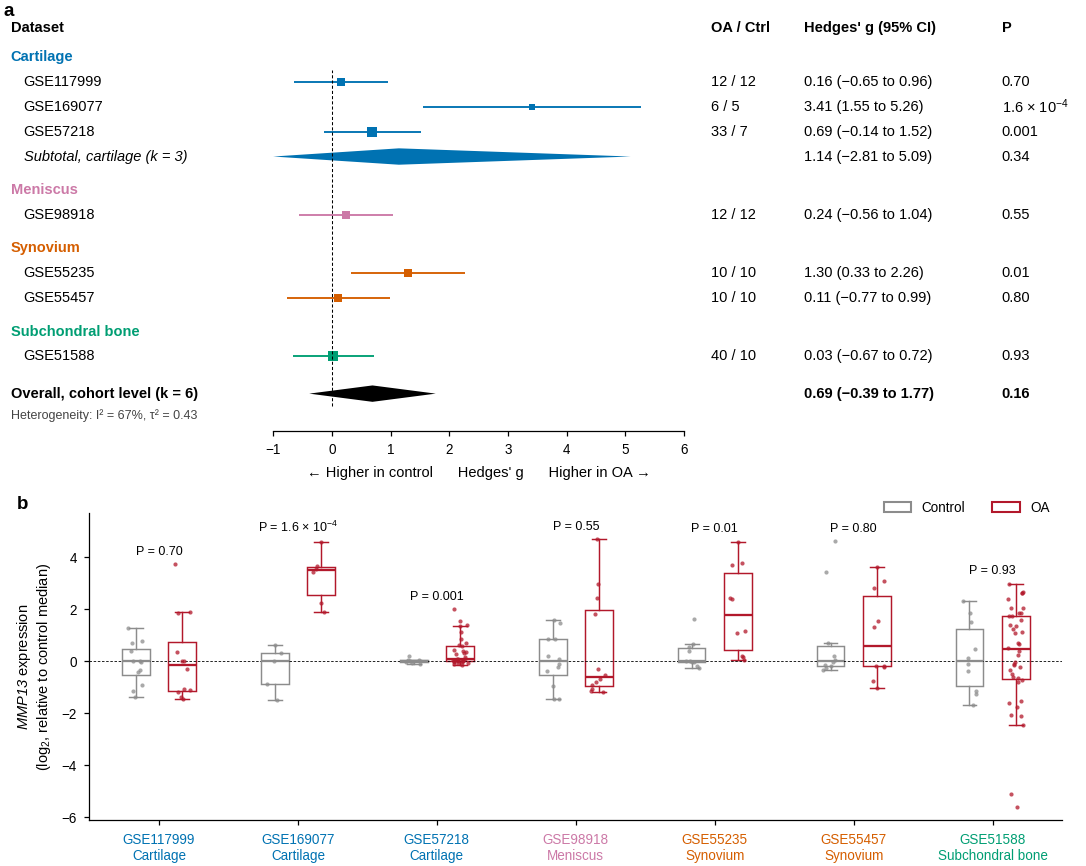

In [6]:
# [module-A]
rows = []
for acc in ordered_datasets():
    d = DATA[acc]; x = d["expr"].loc[TARGET]; gr = d["groups"]
    x1, x0 = x[gr == "OA"].values, x[gr == "Control"].values
    g, v = hedges_g(x1, x0)
    rows.append(dict(dataset=acc, tissue=d["tissue"], cohort=d["cohort"], n_OA=len(x1), n_control=len(x0),
                     mean_OA=x1.mean(), mean_control=x0.mean(), log2FC=x1.mean() - x0.mean(),
                     hedges_g=g, var=v, lo=g - 1.96 * np.sqrt(v), hi=g + 1.96 * np.sqrt(v),
                     welch_p=stats.ttest_ind(x1, x0, equal_var=False).pvalue,
                     mannwhitney_p=stats.mannwhitneyu(x1, x0).pvalue))
A = pd.DataFrame(rows)
COH = cohort_aggregate(A)
META = meta_re(COH.g, COH["var"])
META_T = {t: meta_re(s.hedges_g, s["var"]) for t, s in A.groupby("tissue")}
A.to_csv(os.path.join(DIRS["tables"], "T1_MMP13_effect_sizes.csv"), index=False)

# --- age by group, where GEO annotation provides it (potential confounder)
AGE = []
for acc in ordered_datasets():
    an = pd.read_csv(os.path.join(DIRS["proc"], f"{acc}_annotation.csv"), index_col=0)
    col = next((c for c in an.columns if re.search(r"^ch_(.*[^a-z])?age\b", c)), None)
    if col is None:
        continue
    age = pd.to_numeric(an[col].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
    gr = DATA[acc]["groups"]
    a_c, a_o = age.reindex(gr[gr == "Control"].index).dropna(), age.reindex(gr[gr == "OA"].index).dropna()
    if len(a_c) >= 3 and len(a_o) >= 3:
        AGE.append(dict(dataset=acc, control_median_age=a_c.median(), control_range=f"{a_c.min():.0f}–{a_c.max():.0f}",
                        OA_median_age=a_o.median(), OA_range=f"{a_o.min():.0f}–{a_o.max():.0f}",
                        mannwhitney_p=stats.mannwhitneyu(a_o, a_c).pvalue))
AGE = pd.DataFrame(AGE)
AGE.to_csv(os.path.join(DIRS["tables"], "S2_age_by_group.csv"), index=False)
if len(AGE):
    print("\nAge by group (from GEO annotation):"); print(AGE.round(3).to_string(index=False))
pd.DataFrame({**{"All tissues (cohort-level)": META}, **META_T}).drop("weights").T \
  .to_csv(os.path.join(DIRS["tables"], "T1b_MMP13_meta_analysis.csv"))
print(f"Pooled (k = {META['k']} cohorts): g = {META['g']:.2f} [HKSJ 95% CI {META['lo']:.2f}, {META['hi']:.2f}], "
      f"p = {fmt_p(META['p'])}, I² = {META['I2']:.0f}%, τ² = {META['tau2']:.2f}")
for t in TISSUE_ORDER:
    if t in META_T:
        m = META_T[t]
        print(f"  {t:17s} k={m['k']}  g = {m['g']:.2f} [{m['lo']:.2f}, {m['hi']:.2f}]  p = {fmt_p(m['p'])}")

# ----- Figure 1  (fixed-geometry layout: text columns live inside the 183-mm figure)
def num(x, d=2):
    return f"{x:.{d}f}".replace("-", "−")

rowsF, y = [], 0
for t in TISSUE_ORDER:
    s = A[A.tissue == t]
    if not len(s): continue
    rowsF.append(dict(kind="header", label=t, y=y)); y -= 1
    for r in s.itertuples():
        rowsF.append(dict(kind="study", r=r, y=y)); y -= 1
    if len(s) >= 3:                                   # HKSJ subtotal only when ≥3 datasets
        rowsF.append(dict(kind="sub", m=META_T[t], tissue=t, y=y)); y -= 1
    y -= 0.35
rowsF.append(dict(kind="overall", m=META, y=y - 0.15))
rowsF.append(dict(kind="het", y=y - 1.05))
n_rows = -y + 2

fig = plt.figure(figsize=(W2, (n_rows * 4.6 + 82) * MM))
H = fig.get_figheight()
top_h = (n_rows * 4.6 * MM) / H
ax_l = fig.add_axes([0.0, 1 - top_h - 0.02, 0.24, top_h])
ax_f = fig.add_axes([0.25, 1 - top_h - 0.02, 0.38, top_h], sharey=ax_l)
ax_r = fig.add_axes([0.655, 1 - top_h - 0.02, 0.345, top_h], sharey=ax_l)
for a_ in (ax_l, ax_r):
    a_.axis("off")
ax_f.spines["left"].set_visible(False); ax_f.tick_params(axis="y", left=False, labelleft=False)
y_head = 0.9
ax_l.text(0.03, y_head, "Dataset", fontweight="bold", va="bottom")
for xx, h in [(0.0, "OA / Ctrl"), (0.25, "Hedges' g (95% CI)"), (0.78, "P")]:
    ax_r.text(xx, y_head, h, fontweight="bold", va="bottom")
lo_all = [rf["r"].lo for rf in rowsF if rf["kind"] == "study"] + [META["lo"]]
hi_all = [rf["r"].hi for rf in rowsF if rf["kind"] == "study"] + [META["hi"]]
xmin, xmax = np.floor(min(lo_all) - 0.2), np.ceil(max(hi_all) + 0.2)
for rf in rowsF:
    yy = rf["y"]
    if rf["kind"] == "header":
        ax_l.text(0.03, yy, rf["label"], fontweight="bold", color=TISSUE_COL[rf["label"]], va="center")
    elif rf["kind"] == "study":
        r = rf["r"]; c = TISSUE_COL[r.tissue]
        ax_f.plot([r.lo, r.hi], [yy, yy], color=c, lw=0.9, solid_capstyle="butt")
        ax_f.plot(r.hedges_g, yy, "s", ms=2.5 + 0.05 * (r.n_OA + r.n_control), color=c, mec="none")
        ax_l.text(0.08, yy, r.dataset, va="center")
        ax_r.text(0.0, yy, f"{r.n_OA} / {r.n_control}", va="center")
        ax_r.text(0.25, yy, f"{num(r.hedges_g)} ({num(r.lo)} to {num(r.hi)})", va="center")
        ax_r.text(0.78, yy, fmt_p(r.welch_p), va="center")
    elif rf["kind"] in ("sub", "overall"):
        m = rf["m"]; c = TISSUE_COL[rf["tissue"]] if rf["kind"] == "sub" else "black"
        lo_c, hi_c = max(m["lo"], xmin), min(m["hi"], xmax)
        ax_f.fill([lo_c, m["g"], hi_c, m["g"]], [yy, yy + 0.33, yy, yy - 0.33], color=c, lw=0)
        bold = "bold" if rf["kind"] == "overall" else None
        lab = (f"Subtotal, {rf['tissue'].lower()} (k = {m['k']})" if rf["kind"] == "sub"
               else f"Overall, cohort level (k = {m['k']})")
        ax_l.text(0.08 if rf["kind"] == "sub" else 0.03, yy, lab, va="center", fontweight=bold,
                  fontstyle="italic" if rf["kind"] == "sub" else None)
        ax_r.text(0.25, yy, f"{num(m['g'])} ({num(m['lo'])} to {num(m['hi'])})", va="center", fontweight=bold)
        ax_r.text(0.78, yy, fmt_p(m["p"]), va="center", fontweight=bold)
    elif rf["kind"] == "het":
        ax_l.text(0.03, yy, f"Heterogeneity: I² = {META['I2']:.0f}%, τ² = {num(META['tau2'])}",
                  va="center", fontsize=6, color="#444444")
y_bottom = min(rf["y"] for rf in rowsF if rf["kind"] != "het")
ax_f.plot([0, 0], [y_bottom - 0.5, -0.5], color="black", lw=0.5, ls=(0, (3, 2)))
ax_f.set_xlim(xmin, xmax); ax_l.set_ylim(min(rf["y"] for rf in rowsF) - 0.6, y_head + 0.9)
ax_f.set_xlabel("\u2190 Higher in control      Hedges' g      Higher in OA \u2192")
ax_l.text(0.0, y_head + 0.6, "a", fontsize=9, fontweight="bold", va="bottom")

bot_h = (52 * MM) / H
ax = fig.add_axes([0.08, (13 * MM) / H, 0.90, bot_h])
src_b = []
order = ordered_datasets()
rng_b = np.random.default_rng(SEED)
for i, acc in enumerate(order):
    d = DATA[acc]; x = d["expr"].loc[TARGET]; gr = d["groups"]
    ref = x[gr == "Control"].median()
    for j, g_ in enumerate(["Control", "OA"]):
        vals = (x[gr == g_] - ref).values; xp = i * 3 + j
        ax.boxplot(vals, positions=[xp], widths=0.6, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor="white", edgecolor=GROUP_COL[g_], lw=0.7),
                   medianprops=dict(color=GROUP_COL[g_], lw=1.1), whiskerprops=dict(color=GROUP_COL[g_], lw=0.7),
                   capprops=dict(color=GROUP_COL[g_], lw=0.7))
        ax.scatter(xp + rng_b.uniform(-0.17, 0.17, len(vals)), vals, s=4, color=GROUP_COL[g_], alpha=0.75, lw=0, zorder=3)
        src_b.append(pd.DataFrame({"dataset": acc, "group": g_, "sample": x[gr == g_].index,
                                   "MMP13_log2_minus_ctrl_median": vals}))
    top = (x - ref).max()
    ax.text(i * 3 + 0.5, top + 0.25, f"P = {fmt_p(A.set_index('dataset').loc[acc, 'welch_p'])}",
            ha="center", va="bottom", fontsize=6)
ax.set_xticks([i * 3 + 0.5 for i in range(len(order))])
ax.set_xticklabels([ds_label(a) for a in order])
for tl, a in zip(ax.get_xticklabels(), order):
    tl.set_color(TISSUE_COL[DATA[a]["tissue"]])
ax.axhline(0, color="black", lw=0.4, ls=(0, (3, 2)))
ax.set_ylabel(f"{italic(TARGET)} expression\n(log$_2$, relative to control median)")
ax.set_xlim(-1, len(order) * 3 - 1)
ymax_b = max((DATA[a]["expr"].loc[TARGET] - DATA[a]["expr"].loc[TARGET][DATA[a]["groups"] == "Control"].median()).max()
             for a in order)
ax.set_ylim(top=ymax_b + 1.0)
ax.legend(handles=[Patch(facecolor="white", edgecolor=GROUP_COL[g], label=g) for g in GROUP_COL],
          loc="upper right", ncol=2, bbox_to_anchor=(1, 1.08))
panel(ax, "b", x=-0.075, y=1.0)
save(fig, "Figure1_MMP13_cross_tissue", pd.concat(src_b))
plt.show()

## B · Balance indices vs MMP13 alone (Figure 2)
CSI = z(MMP13) − z(TIMP3); MTB = mean z(catabolic) − mean z(anabolic); hypertrophy score = mean z(hypertrophy genes).
AUCs with 1,000-sample bootstrap 95% CIs.

saved Figure2_balance_indices  (.png/.tiff 300 dpi, .pdf vector)


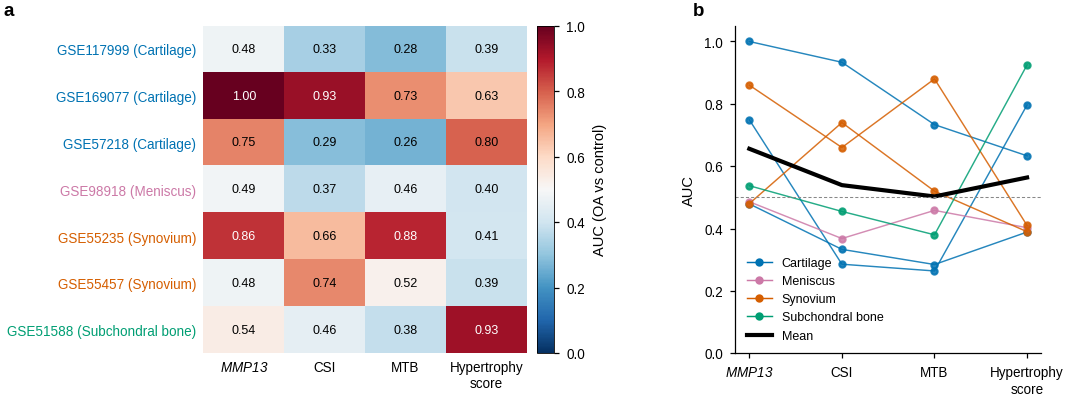

feature
MMP13 alone          0.656
CSI                  0.539
MTB                  0.503
Hypertrophy score    0.564
Name: AUC, dtype: float64


In [7]:
# [module-B]
FEATS = ["MMP13 alone", "CSI", "MTB", "Hypertrophy score"]
rowsB = []
for acc in ordered_datasets():
    d = DATA[acc]; ez = zrows(d["expr"]); gr = d["groups"]; y = (gr == "OA").astype(int).values
    f = {"MMP13 alone": ez.loc[TARGET],
         "CSI": ez.loc[TARGET] - ez.loc["TIMP3"] if "TIMP3" in ez.index else None,
         "MTB": score(ez, CATABOLIC) - score(ez, ANABOLIC),
         "Hypertrophy score": score(ez, HYPERTROPHY)}
    for k_, v_ in f.items():
        if v_ is None or v_.isna().all(): continue
        lo, hi = boot_auc(y, v_.values)
        rowsB.append(dict(dataset=acc, tissue=d["tissue"], feature=k_, AUC=roc_auc_score(y, v_.values), lo=lo, hi=hi))
B = pd.DataFrame(rowsB)
B.to_csv(os.path.join(DIRS["tables"], "T2_balance_index_AUC.csv"), index=False)

fig, axs = plt.subplots(1, 2, figsize=(W2, 72 * MM), gridspec_kw=dict(width_ratios=[1.15, 1], wspace=0.55))
ax = axs[0]
M = B.pivot(index="dataset", columns="feature", values="AUC").loc[ordered_datasets(), FEATS]
im = ax.imshow(M.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v_ = M.values[i, j]
        ax.text(j, i, f"{v_:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v_ - 0.5) > 0.3 else "black")
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels([italic("MMP13"), "CSI", "MTB", "Hypertrophy\nscore"])
ax.set_yticks(range(len(M))); ax.set_yticklabels([ds_label(a, False) for a in M.index])
for tl, a in zip(ax.get_yticklabels(), M.index):
    tl.set_color(TISSUE_COL[DATA[a]["tissue"]])
for s_ in ax.spines.values(): s_.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03); cb.set_label("AUC (OA vs control)"); cb.outline.set_linewidth(0.4)
panel(ax, "a", x=-0.62)

ax = axs[1]
for acc in ordered_datasets():
    s = B[B.dataset == acc].set_index("feature").reindex(FEATS)
    ax.plot(range(len(FEATS)), s.AUC, "-o", ms=3, lw=0.7, color=TISSUE_COL[DATA[acc]["tissue"]], alpha=0.85)
mean_auc = B.groupby("feature").AUC.mean().reindex(FEATS)
ax.plot(range(len(FEATS)), mean_auc, "-", lw=2, color="black", label="Mean")
ax.axhline(0.5, color="#888888", lw=0.5, ls=(0, (3, 2)))
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels([italic("MMP13"), "CSI", "MTB", "Hypertrophy\nscore"])
ax.set_ylabel("AUC"); ax.set_ylim(0, 1.05)
ax.legend(handles=[Line2D([], [], color=TISSUE_COL[t], marker="o", ms=3, lw=0.7, label=t)
                   for t in TISSUE_ORDER if t in set(A.tissue)] + [Line2D([], [], color="black", lw=2, label="Mean")],
          loc="lower left", fontsize=6)
panel(ax, "b")
save(fig, "Figure2_balance_indices", B)
plt.show()
print(mean_auc.round(3))

## C · Consensus MMP13 co-expression neighbourhood within OA tissue (Figure 3)
Within-OA Spearman ρ per dataset → Fisher z → averaged within cohort → sample-size-weighted Stouffer across cohorts.

Genes tested: 18259 | robust partners (FDR < 0.05, ≥75% cohort sign agreement): 1510 positive, 407 negative
Top +: OLFML2B, THY1, THBS2, GJA1, COL5A2, AEBP1, MMP9, FAT1, CTSK, TMEM119, SRPX, MMP11, LEF1, SPP1, POSTN
Top −: GRK5, TIMP4, CIDEA, GBP4, VIPR1, SLC48A1, STOX2, BOK, HOXA5, LOC644662, RNF157, ABCA6, NDRG2, FBXO27, ECHDC2
saved Figure3_MMP13_neighbourhood  (.png/.tiff 300 dpi, .pdf vector)


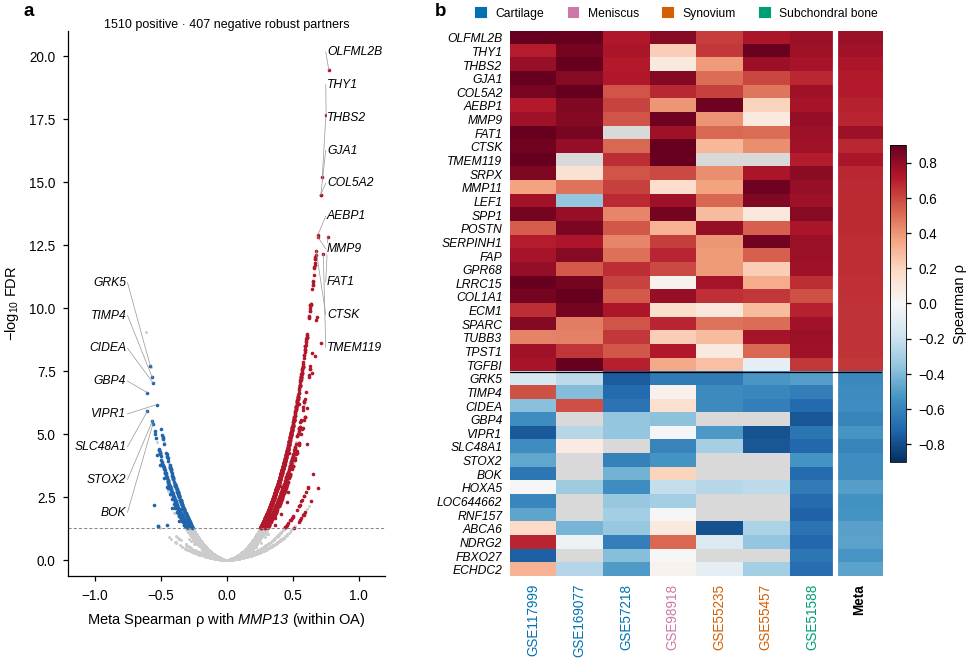

In [8]:
# [module-C]
RHO, NS = {}, {}
for acc in ordered_datasets():
    d = DATA[acc]; gr = d["groups"]
    sub = d["expr"].loc[:, gr == "OA"] if (gr == "OA").sum() >= MIN_OA_FOR_COEXP else d["expr"]
    sub = sub.loc[sub.std(axis=1) > 0]
    RHO[acc] = spearman_vs(sub, sub.loc[TARGET].values); NS[acc] = sub.shape[1]
RHO = pd.DataFrame(RHO).drop(index=TARGET, errors="ignore"); NS = pd.Series(NS)
Zd = np.arctanh(RHO.clip(-0.999, 0.999))
Zc, Nc = {}, {}
for c, accs in COHORT.groupby(COHORT):
    Zc[c] = Zd[list(accs.index)].mean(axis=1); Nc[c] = NS[list(accs.index)].mean()
Zc = pd.DataFrame(Zc); Nc = pd.Series(Nc)
Wc = Nc - 3; av = Zc.notna()
C = pd.DataFrame({
    "meta_rho": np.tanh((Zc * Wc).sum(axis=1) / (av * Wc).sum(axis=1)),
    "meta_z": (Zc * Wc).sum(axis=1) / np.sqrt((av * Wc).sum(axis=1)),
    "n_cohorts": av.sum(axis=1)})
C["sign_consistency"] = (np.sign(Zc).eq(np.sign(C.meta_rho), axis=0) & av).sum(axis=1) / C.n_cohorts
C["p"] = 2 * stats.norm.sf(C.meta_z.abs())
C = C[C.n_cohorts >= max(2, int(np.ceil(Zc.shape[1] / 2)))]
C["FDR"] = multipletests(C.p, method="fdr_bh")[1]
C = C.join(RHO.add_prefix("rho_")).sort_values("meta_z", ascending=False)
C.to_csv(os.path.join(DIRS["tables"], "T3_MMP13_coexpression_consensus.csv"))
ROB = C[(C.FDR < 0.05) & (C.sign_consistency >= 0.75)]
POS = ROB[ROB.meta_rho > 0].sort_values("meta_z", ascending=False)
NEG = ROB[ROB.meta_rho < 0].sort_values("meta_z")
print(f"Genes tested: {len(C)} | robust partners (FDR < 0.05, ≥75% cohort sign agreement): "
      f"{len(POS)} positive, {len(NEG)} negative")
print("Top +:", ", ".join(POS.index[:15])); print("Top −:", ", ".join(NEG.index[:15]))

fig = plt.figure(figsize=(W2, 120 * MM))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.25], wspace=0.35)
ax = fig.add_subplot(gs[0])
yv = -np.log10(C.FDR.clip(lower=1e-30))
ax.scatter(C.meta_rho, yv, s=2, color="#CCCCCC", lw=0, rasterized=True)
ax.scatter(POS.meta_rho, -np.log10(POS.FDR.clip(lower=1e-30)), s=3, color=POS_COL, lw=0, rasterized=True)
ax.scatter(NEG.meta_rho, -np.log10(NEG.FDR.clip(lower=1e-30)), s=3, color=NEG_COL, lw=0, rasterized=True)
ax.axhline(-np.log10(0.05), color="#888888", lw=0.5, ls=(0, (3, 2)))
ymax3 = float(yv.max()) * 1.08
xr = max(abs(C.meta_rho.min()), abs(C.meta_rho.max()))
ax.set_xlim(-xr * 1.55, xr * 1.55); ax.set_ylim(-0.03 * ymax3, ymax3)
for genes_, side in [(list(POS.index[:10]), 1), (list(NEG.index[:8]), -1)]:
    if not genes_: continue
    py_ = -np.log10(C.loc[genes_, "FDR"].clip(lower=1e-30)).values
    step = ymax3 * 0.062
    centre = np.clip(py_.mean(), 0.08 * ymax3 + step * (len(genes_) - 1) / 2, 0.96 * ymax3 - step * (len(genes_) - 1) / 2)
    ys = centre + step * ((len(genes_) - 1) / 2 - np.arange(len(genes_)))
    order_ = np.argsort(-py_); genes_ = [genes_[k] for k in order_]
    for g, ty in zip(genes_, ys):
        px, py = C.loc[g, "meta_rho"], -np.log10(max(C.loc[g, "FDR"], 1e-30))
        tx = side * xr * 0.97
        ax.plot([px, tx], [py, ty], color="#999999", lw=0.35, zorder=1)
        ax.text(tx + side * 0.01, ty, g, fontsize=5.8, fontstyle="italic", va="center",
                ha="left" if side > 0 else "right", bbox=dict(fc="white", ec="none", pad=0.2), zorder=4)
ax.set_xlabel(f"Meta Spearman ρ with {italic(TARGET)} (within OA)")
ax.set_ylabel("−log$_{10}$ FDR")
ax.text(0.5, 1.0, f"{len(POS)} positive · {len(NEG)} negative robust partners", transform=ax.transAxes,
        ha="center", va="bottom", fontsize=6)
panel(ax, "a")

ax = fig.add_subplot(gs[1])
top = pd.concat([POS.head(25), NEG.head(15)])
dcols = [f"rho_{a}" for a in ordered_datasets()]
Hm = top[dcols].copy(); Hm["meta"] = top.meta_rho
cm_nan = mpl.colormaps["RdBu_r"].copy(); cm_nan.set_bad("#D9D9D9")
im = ax.imshow(np.ma.masked_invalid(Hm.values.astype(float)), cmap=cm_nan, vmin=-0.9, vmax=0.9, aspect="auto")
ax.axvline(len(dcols) - 0.5, color="white", lw=2.5)
ax.axhline(len(POS.head(25)) - 0.5, color="black", lw=0.6)
ax.set_yticks(range(len(Hm))); ax.set_yticklabels(Hm.index, fontstyle="italic", fontsize=5.8)
ax.set_xticks(range(Hm.shape[1]))
ax.set_xticklabels([a for a in ordered_datasets()] + ["Meta"], rotation=90)
for tl, a in zip(ax.get_xticklabels(), ordered_datasets()):
    tl.set_color(TISSUE_COL[DATA[a]["tissue"]])
ax.get_xticklabels()[-1].set_fontweight("bold")
for s_ in ax.spines.values(): s_.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Spearman ρ"); cb.outline.set_linewidth(0.4)
ax.legend(handles=[Patch(color=TISSUE_COL[t], label=t) for t in TISSUE_ORDER if t in set(A.tissue)],
          loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=4, fontsize=5.8, handlelength=0.8)
panel(ax, "b", x=-0.2)
save(fig, "Figure3_MMP13_neighbourhood", top[["meta_rho", "FDR", "n_cohorts", "sign_consistency"] + dcols])
plt.show()

## P · Within-patient test: lesioned vs preserved cartilage (Figure 7)
Datasets with paired lesioned/preserved samples from the same joint (GSE57218). Paired Wilcoxon signed-rank tests.
The neighbourhood scores use partners derived **without** that dataset's cohort (leave-one-cohort-out), avoiding circularity.

saved Figure7_lesioned_vs_preserved  (.png/.tiff 300 dpi, .pdf vector)


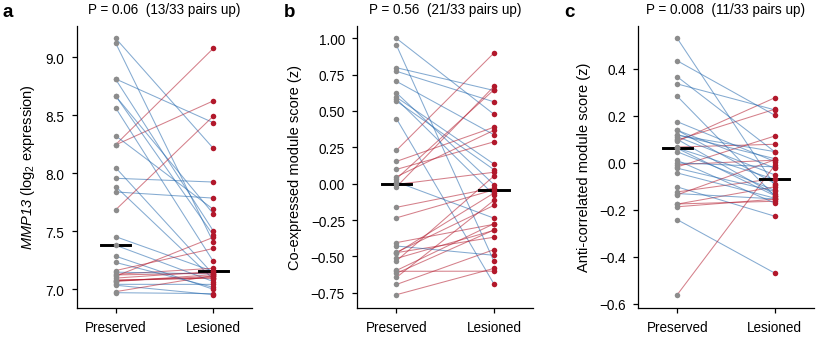

,dataset,feature,n_pairs,median_preserved,median_lesioned,median_paired_difference,n_higher_in_lesion,wilcoxon_p
0,GSE57218,MMP13,33,7.3799,7.1546,-0.0320,13,0.0626
1,GSE57218,Co-expressed module (top 50),33,-0.0048,-0.0417,0.1336,21,0.5602
2,GSE57218,Anti-correlated module (top 50),33,0.0623,-0.0663,-0.1073,11,0.0078


In [9]:
# [module-P]
PAIR_RES = []
for acc, (ex_all, an_all, pc) in PAIRED_RAW.items():
    pid = an_all["text"].str.extract(pc["pair_re"])[0]
    case = an_all["text"].str.contains(pc["case_re"], regex=True)
    ref = an_all["text"].str.contains(pc["ref_re"], regex=True)
    tab = pd.DataFrame({"pid": pid, "case": case, "ref": ref}).dropna(subset=["pid"])
    pairs = [(tab[(tab.pid == p) & tab.ref].index[0], tab[(tab.pid == p) & tab.case].index[0])
             for p in tab.pid.unique() if ((tab.pid == p) & tab.ref).sum() == 1 and ((tab.pid == p) & tab.case).sum() == 1]
    if len(pairs) < 6:
        print(f"{acc}: only {len(pairs)} complete pairs — skipped"); continue
    coh = DATASETS[acc]["cohort"]
    keep_c = [c for c in Zc.columns if c != coh]
    Zl = Zc[keep_c]; avl = Zl.notna(); Wl = Wc[keep_c]
    mz = ((Zl * Wl).sum(axis=1) / np.sqrt((avl * Wl).sum(axis=1)))[avl.sum(axis=1) >= max(2, int(np.ceil(len(keep_c) / 2)))]
    pos_l = [g for g in mz.sort_values(ascending=False).index[:50] if g in ex_all.index]
    neg_l = [g for g in mz.sort_values().index[:50] if g in ex_all.index]
    cols = [c for pr in pairs for c in pr]
    ez = zrows(ex_all[cols])
    ref_s, case_s = [p[0] for p in pairs], [p[1] for p in pairs]
    out = {}
    for name, vec in {TARGET: ex_all.loc[TARGET, cols], "Co-expressed module (top 50)": score(ez, pos_l),
                      "Anti-correlated module (top 50)": score(ez, neg_l)}.items():
        a_, b_ = vec[ref_s].values, vec[case_s].values
        w = stats.wilcoxon(b_, a_)
        out[name] = (a_, b_, w.pvalue)
        PAIR_RES.append(dict(dataset=acc, feature=name, n_pairs=len(pairs), median_preserved=np.median(a_),
                             median_lesioned=np.median(b_), median_paired_difference=np.median(b_ - a_),
                             n_higher_in_lesion=int((b_ > a_).sum()), wilcoxon_p=w.pvalue))
    fig, axs = plt.subplots(1, 3, figsize=(W2 * 0.88, 62 * MM), gridspec_kw=dict(wspace=0.6))
    ylabs = [f"{italic(TARGET)} (log$_2$ expression)", "Co-expressed module score (z)", "Anti-correlated module score (z)"]
    for ax, (name, (a_, b_, p_)), yl, letter in zip(axs, out.items(), ylabs, "abc"):
        for u, v in zip(a_, b_):
            ax.plot([0, 1], [u, v], color=POS_COL if v > u else NEG_COL, lw=0.5, alpha=0.55)
        ax.scatter(np.zeros(len(a_)), a_, s=7, color=GROUP_COL["Control"], zorder=3, lw=0)
        ax.scatter(np.ones(len(b_)), b_, s=7, color=GROUP_COL["OA"], zorder=3, lw=0)
        ax.plot([-0.15, 0.15], [np.median(a_)] * 2, color="black", lw=1.4)
        ax.plot([0.85, 1.15], [np.median(b_)] * 2, color="black", lw=1.4)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Preserved", "Lesioned"]); ax.set_xlim(-0.4, 1.4)
        ax.set_ylabel(yl)
        ax.set_title(f"P = {fmt_p(p_)}  ({int((b_ > a_).sum())}/{len(a_)} pairs up)", fontsize=6.5)
        panel(ax, letter, x=-0.42)
    save(fig, "Figure7_lesioned_vs_preserved", pd.DataFrame(
        {f"{k}_{side}": v for k, (a_, b_, _) in out.items() for side, v in (("preserved", a_), ("lesioned", b_))},
        index=[f"pair_{i+1}" for i in range(len(pairs))]))
    plt.show()
PAIR = pd.DataFrame(PAIR_RES)
PAIR.to_csv(os.path.join(DIRS["tables"], "T9_paired_lesioned_vs_preserved.csv"), index=False)
PAIR.round(4)

## D · MMP13 coupling to matrix and hypertrophy programmes (Figure 4)

saved Figure4_programme_coupling  (.png/.tiff 300 dpi, .pdf vector)


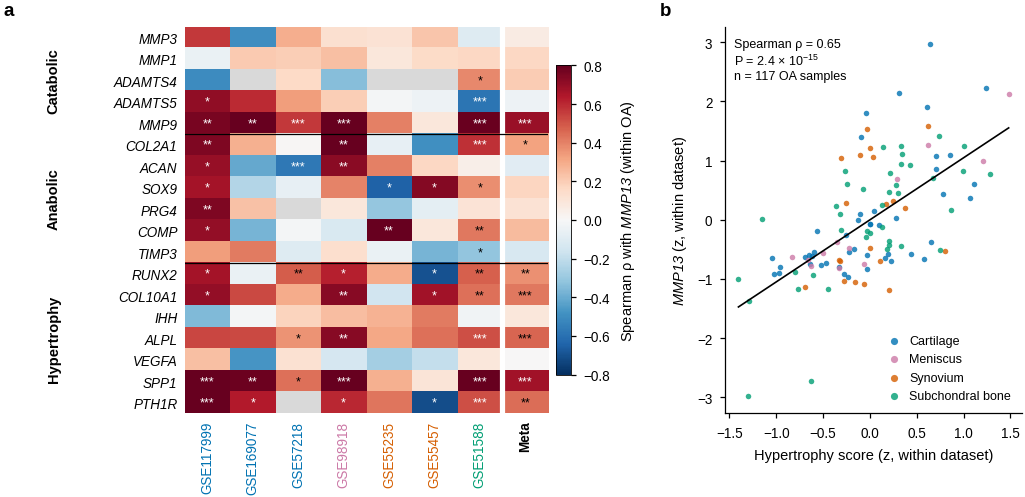

Pooled within-OA MMP13 vs hypertrophy score: ρ = 0.65, P = 2.4 × 10$^{-15}$, n = 117


In [10]:
# [module-D]
prog = [(g, "Catabolic") for g in CATABOLIC if g != TARGET] + [(g, "Anabolic") for g in ANABOLIC] + \
       [(g, "Hypertrophy") for g in HYPERTROPHY]
prog = [(g, p_) for g, p_ in prog if g in C.index]
genes = [g for g, _ in prog]
dcols = [f"rho_{a}" for a in ordered_datasets()]
Hd = C.loc[genes, dcols].copy()
Pd = pd.DataFrame({c: rho_p(Hd[c], NS[c[4:]]) for c in dcols}, index=genes)
Hd["meta"] = C.loc[genes, "meta_rho"]; Pd["meta"] = C.loc[genes, "FDR"]

pooled = []
for acc in ordered_datasets():
    d = DATA[acc]; oa = d["expr"].loc[:, d["groups"] == "OA"]
    if oa.shape[1] < MIN_OA_FOR_COEXP: continue
    ez = zrows(oa)
    pooled.append(pd.DataFrame({"dataset": acc, "tissue": d["tissue"], "MMP13_z": ez.loc[TARGET],
                                "hypertrophy_z": score(ez, [g for g in HYPERTROPHY if g != TARGET])}))
pooled = pd.concat(pooled)
r_all, p_all = stats.spearmanr(pooled.MMP13_z, pooled.hypertrophy_z)

fig, axs = plt.subplots(1, 2, figsize=(W2, 85 * MM), gridspec_kw=dict(width_ratios=[1.3, 1], wspace=0.45))
ax = axs[0]
cm_nan = mpl.colormaps["RdBu_r"].copy(); cm_nan.set_bad("#D9D9D9")
im = ax.imshow(np.ma.masked_invalid(Hd.values.astype(float)), cmap=cm_nan, vmin=-0.8, vmax=0.8, aspect="auto")
for i in range(Hd.shape[0]):
    for j in range(Hd.shape[1]):
        p_ = Pd.values[i, j]
        if p_ < 0.05:
            ax.text(j, i, "*" if p_ >= 0.01 else "**" if p_ >= 0.001 else "***", ha="center", va="center",
                    fontsize=6, color="white" if abs(Hd.values[i, j]) > 0.5 else "black")
ax.axvline(len(dcols) - 0.5, color="white", lw=2.5)
bounds = np.cumsum([sum(1 for _, p_ in prog if p_ == k) for k in ["Catabolic", "Anabolic", "Hypertrophy"]])
for b in bounds[:-1]:
    ax.axhline(b - 0.5, color="black", lw=0.6)
ax.set_yticks(range(len(genes))); ax.set_yticklabels(genes, fontstyle="italic")
start = 0
for k, b in zip(["Catabolic", "Anabolic", "Hypertrophy"], bounds):
    ax.text(-0.36, (start + b - 1) / 2, k, transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData),
            rotation=90, ha="center", va="center", fontweight="bold"); start = b
ax.set_xticks(range(Hd.shape[1])); ax.set_xticklabels(ordered_datasets() + ["Meta"], rotation=90)
for tl, a in zip(ax.get_xticklabels(), ordered_datasets()):
    tl.set_color(TISSUE_COL[DATA[a]["tissue"]])
ax.get_xticklabels()[-1].set_fontweight("bold")
for s_ in ax.spines.values(): s_.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label(f"Spearman ρ with {italic(TARGET)} (within OA)")
cb.outline.set_linewidth(0.4)
panel(ax, "a", x=-0.5)

ax = axs[1]
for t in TISSUE_ORDER:
    s = pooled[pooled.tissue == t]
    if len(s): ax.scatter(s.hypertrophy_z, s.MMP13_z, s=7, color=TISSUE_COL[t], lw=0, alpha=0.8, label=t)
b1, b0 = np.polyfit(pooled.hypertrophy_z, pooled.MMP13_z, 1)
xx = np.linspace(pooled.hypertrophy_z.min(), pooled.hypertrophy_z.max(), 50)
ax.plot(xx, b0 + b1 * xx, color="black", lw=0.8)
ax.text(0.03, 0.97, f"Spearman ρ = {r_all:.2f}\nP = {fmt_p(p_all)}\nn = {len(pooled)} OA samples",
        transform=ax.transAxes, va="top", fontsize=6)
ax.set_xlabel("Hypertrophy score (z, within dataset)"); ax.set_ylabel(f"{italic(TARGET)} (z, within dataset)")
ax.legend(loc="lower right", fontsize=6, handletextpad=0.2, markerscale=1.3)
panel(ax, "b", x=-0.22)
save(fig, "Figure4_programme_coupling", Hd.join(Pd.add_suffix("_p_or_FDR")))
plt.show()
D = Hd.join(Pd.add_suffix("_p_or_FDR")); D.to_csv(os.path.join(DIRS["tables"], "T4_programme_coupling.csv"))
print(f"Pooled within-OA MMP13 vs hypertrophy score: ρ = {r_all:.2f}, P = {fmt_p(p_all)}, n = {len(pooled)}")

## E · Hallmark programmes tracking MMP13 within OA tissue (Figure 5)
**a — consensus (primary):** all genes ranked by the cohort-level co-expression meta-z with MMP13 (Module C) →
pre-ranked GSEA on MSigDB Hallmark 2020. Uses every cohort and every OA sample.
**b — sensitivity:** in datasets with ≥ `MIN_OA_FOR_ENDO` OA samples, MMP13-high vs MMP13-low tertile contrast
(Welch t ranking → pre-ranked GSEA). Small tertile groups (e.g. 4 vs 4) inflate GSEA, so they are not used.

Consensus GSEA: 32 Hallmark sets at FDR < 0.05
GSE57218: 11 MMP13-high vs 11 MMP13-low OA samples
GSE51588: 14 MMP13-high vs 13 MMP13-low OA samples
saved Figure5_MMP13_hallmark_programmes  (.png/.tiff 300 dpi, .pdf vector)


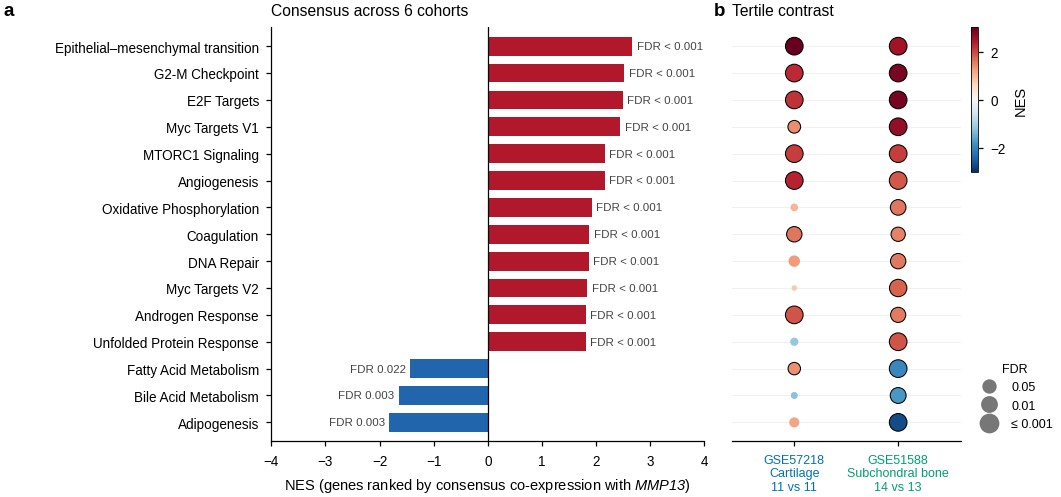

In [11]:
# [module-E]
import gseapy as gp
def run_prerank(rnk):
    res = gp.prerank(rnk=rnk.sort_values(ascending=False), gene_sets="MSigDB_Hallmark_2020",
                     permutation_num=GSEA_PERMUTATIONS, min_size=10, max_size=500, seed=SEED,
                     outdir=None, threads=2, verbose=False).res2d
    res["NES"] = res["NES"].astype(float); res["FDR q-val"] = res["FDR q-val"].astype(float)
    return res.set_index("Term")

# a) consensus ranking
rnk_meta = C["meta_z"].replace([np.inf, -np.inf], np.nan).dropna()
rnk_meta = rnk_meta + np.random.default_rng(SEED).normal(0, 1e-9, len(rnk_meta))
try:
    GS_META = run_prerank(rnk_meta)
    GS_META.to_csv(os.path.join(DIRS["tables"], "T5a_consensus_hallmark_GSEA.csv"))
    print(f"Consensus GSEA: {int((GS_META['FDR q-val'] < 0.05).sum())} Hallmark sets at FDR < 0.05")
except Exception as e:
    GS_META = pd.DataFrame(); print("Consensus GSEA failed —", e)

# b) tertile contrast in larger datasets
NES, FDRq, ENDO_N = {}, {}, {}
for acc in ordered_datasets():
    d = DATA[acc]; oa = d["expr"].loc[:, d["groups"] == "OA"]
    if oa.shape[1] < MIN_OA_FOR_ENDO: continue
    m = oa.loc[TARGET]; hi, lo = m >= m.quantile(2 / 3), m <= m.quantile(1 / 3)
    t, p = stats.ttest_ind(oa.loc[:, hi], oa.loc[:, lo], axis=1, equal_var=False)
    rnk = pd.Series(t, index=oa.index).drop(TARGET, errors="ignore").replace([np.inf, -np.inf], np.nan).dropna()
    rnk = rnk + np.random.default_rng(SEED).normal(0, 1e-9, len(rnk))
    pd.DataFrame({"t": rnk, "p": pd.Series(p, index=oa.index).reindex(rnk.index)}).sort_values("t", ascending=False) \
      .to_csv(os.path.join(DIRS["tables"], f"T5b_tertile_DE_{acc}.csv"))
    try:
        res = run_prerank(rnk); res.to_csv(os.path.join(DIRS["tables"], f"T5b_tertile_GSEA_{acc}.csv"))
        NES[acc], FDRq[acc] = res["NES"], res["FDR q-val"]; ENDO_N[acc] = (int(hi.sum()), int(lo.sum()))
        print(f"{acc}: {hi.sum()} MMP13-high vs {lo.sum()} MMP13-low OA samples")
    except Exception as e:
        print(f"{acc}: GSEA failed — {e}")

def clean_term(t):
    t = t.replace("HALLMARK_", "").replace("_", " ").strip()
    fixes = {"Pperoxisome": "Peroxisome", "heme Metabolism": "Heme metabolism", "PI3K/AKT/mTOR  Signaling":
             "PI3K/AKT/mTOR signaling", "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition"}
    return fixes.get(t, t[:1].upper() + t[1:])

if len(GS_META):
    sig = GS_META[GS_META["FDR q-val"] < 0.05].sort_values("NES")
    if len(sig) > 24:                                   # keep the strongest 12 up / 12 down
        sig = pd.concat([sig[sig.NES < 0].head(12), sig[sig.NES > 0].tail(12)])
    terms = list(sig.index)
    has_b = len(NES) > 0
    fig = plt.figure(figsize=(W2 * 0.86, max(70, 4.2 * len(terms) + 28) * MM))
    gs = fig.add_gridspec(1, 2 if has_b else 1, width_ratios=[1.25, 0.75] if has_b else [1], wspace=0.08)
    ax = fig.add_subplot(gs[0])
    yv = np.arange(len(terms))
    ax.barh(yv, sig.NES, color=[POS_COL if v > 0 else NEG_COL for v in sig.NES], height=0.7)
    for yy, (nes, q) in zip(yv, zip(sig.NES, sig["FDR q-val"])):
        ax.text(nes + (0.08 if nes > 0 else -0.08), yy, "FDR " + ("< 0.001" if q < 0.001 else f"{q:.3f}"),
                va="center", ha="left" if nes > 0 else "right", fontsize=5.5, color="#444444")
    ax.axvline(0, color="black", lw=0.6)
    ax.set_yticks(yv); ax.set_yticklabels([clean_term(t) for t in terms])
    lim = np.ceil(sig.NES.abs().max() + 1.2)
    ax.set_xlim(-lim, lim); ax.set_ylim(-0.7, len(terms) - 0.3)
    ax.set_xlabel(f"NES (genes ranked by consensus co-expression with {italic(TARGET)})")
    ax.set_title(f"Consensus across {Zc.shape[1]} cohorts", loc="left")
    panel(ax, "a", x=-0.62)
    if has_b:
        axb = fig.add_subplot(gs[1], sharey=ax)
        cols = list(NES)
        for j, acc in enumerate(cols):
            nes = NES[acc].reindex(terms).values; q = FDRq[acc].reindex(terms).fillna(1).values
            sz = 6 + 22 * np.clip(-np.log10(np.clip(q, 1e-3, 1)), 0, 3)
            axb.scatter(np.full(len(terms), j), yv, s=sz, c=np.nan_to_num(nes), cmap="RdBu_r", vmin=-3, vmax=3,
                        edgecolors=np.where(q < 0.05, "black", "none"), linewidths=0.5)
        axb.set_xticks(range(len(cols)))
        axb.set_xticklabels([f"{a}\n{DATA[a]['tissue']}\n{ENDO_N[a][0]} vs {ENDO_N[a][1]}" for a in cols], fontsize=6)
        for tl, a in zip(axb.get_xticklabels(), cols):
            tl.set_color(TISSUE_COL[DATA[a]["tissue"]])
        axb.set_xlim(-0.6, len(cols) - 0.4); axb.tick_params(axis="y", labelleft=False, length=0)
        axb.spines["left"].set_visible(False); axb.grid(axis="y", color="#EEEEEE", lw=0.4); axb.set_axisbelow(True)
        axb.set_title("Tertile contrast", loc="left")
        sm = mpl.cm.ScalarMappable(cmap="RdBu_r", norm=mpl.colors.Normalize(-3, 3))
        cb = fig.colorbar(sm, ax=axb, fraction=0.08, pad=0.04, shrink=0.35, anchor=(0, 1)); cb.set_label("NES")
        cb.outline.set_linewidth(0.4)
        hs = [Line2D([], [], marker="o", ls="", color="#777777", ms=np.sqrt(6 + 22 * v), label=l)
              for v, l in [(1.3, "0.05"), (2, "0.01"), (3, "≤ 0.001")]]
        axb.legend(handles=hs, title="FDR", loc="lower left", bbox_to_anchor=(1.02, 0.0), fontsize=6, title_fontsize=6)
        panel(axb, "b", x=-0.08)
    src5 = sig[["NES", "FDR q-val"]].add_prefix("consensus_")
    for acc in NES:
        src5[f"{acc}_NES"] = NES[acc].reindex(terms); src5[f"{acc}_FDR"] = FDRq[acc].reindex(terms)
    save(fig, "Figure5_MMP13_hallmark_programmes", src5)
    plt.show()

## F · Upstream regulators and pathways of the neighbourhood (Figure 6)

saved Figure6_upstream_and_pathways  (.png/.tiff 300 dpi, .pdf vector)


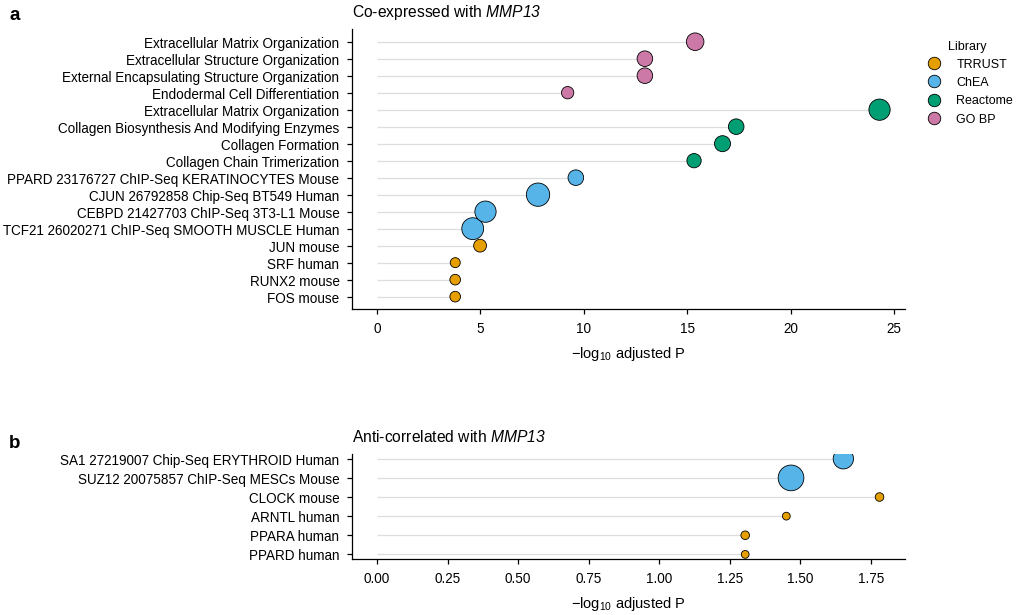

In [12]:
# [module-F]
LIBS = ["TRRUST_Transcription_Factors_2019", "ChEA_2022", "Reactome_2022", "GO_Biological_Process_2023"]
LIB_SHORT = {"TRRUST_Transcription_Factors_2019": "TRRUST", "ChEA_2022": "ChEA", "Reactome_2022": "Reactome",
             "GO_Biological_Process_2023": "GO BP"}
LIB_COL = {"TRRUST": "#E69F00", "ChEA": "#56B4E9", "Reactome": "#009E73", "GO BP": "#CC79A7"}
ENR = []
for label, genes in {"Co-expressed": list(POS.index[:TOP_PARTNERS]),
                     "Anti-correlated": list(NEG.index[:TOP_PARTNERS])}.items():
    if len(genes) < 10: continue
    try:
        e = gp.enrichr(gene_list=genes, gene_sets=LIBS, organism="human", outdir=None,
                       background=list(C.index)).results
        e["direction"] = label; ENR.append(e)
    except Exception as ex:
        print(f"Enrichr failed ({label}): {ex}")
if ENR:
    E = pd.concat(ENR)
    E["library"] = E.Gene_set.map(LIB_SHORT)
    E["n_genes"] = E.Genes.str.split(";").str.len()
    E.to_csv(os.path.join(DIRS["tables"], "T7_neighbourhood_enrichment.csv"), index=False)
    S = E[E["Adjusted P-value"] < 0.05].sort_values("Adjusted P-value").groupby(["direction", "library"]).head(4)
    if len(S):
        dirs = [d_ for d_ in ["Co-expressed", "Anti-correlated"] if d_ in set(S.direction)]
        heights = [max(3, (S.direction == d_).sum()) for d_ in dirs]
        fig, axs = plt.subplots(len(dirs), 1, figsize=(W2 * 0.66, (sum(heights) * 4.3 + 22) * MM),
                                gridspec_kw=dict(height_ratios=heights, hspace=0.75), squeeze=False)
        for ax, d_, letter in zip(axs[:, 0], dirs, "ab"):
            s = S[S.direction == d_].copy()
            s["lib_order"] = s.library.map({k: i for i, k in enumerate(LIB_COL)})
            s = s.sort_values(["lib_order", "Adjusted P-value"], ascending=[True, False])
            s["label"] = s.Term.str.replace(r"\s*\(GO:\d+\)|\s*R-HSA-\d+", "", regex=True) \
                               .map(lambda x: textwrap.shorten(x, 60, placeholder="…"))
            yv = np.arange(len(s))
            ax.hlines(yv, 0, -np.log10(s["Adjusted P-value"]), color="#DDDDDD", lw=0.6)
            ax.scatter(-np.log10(s["Adjusted P-value"]), yv, s=8 + 3 * s.n_genes, c=s.library.map(LIB_COL),
                       lw=0.4, edgecolor="black", zorder=3)
            ax.set_yticks(yv); ax.set_yticklabels(s.label)
            ax.set_xlabel("−log$_{10}$ adjusted P"); ax.set_title(f"{d_} with {italic(TARGET)}", loc="left")
            panel(ax, letter, x=-0.62)
        axs[0, 0].legend(handles=[Line2D([], [], marker="o", ls="", color=c, mec="black", mew=0.4, label=k)
                                  for k, c in LIB_COL.items()], loc="upper left", bbox_to_anchor=(1.01, 1.0),
                         fontsize=6, title="Library", title_fontsize=6)
        save(fig, "Figure6_upstream_and_pathways", S)
        plt.show()
else:
    E = pd.DataFrame()

## G · Druggable partners (Supplementary Figure S1, DGIdb)
Interactions are database records, not evidence of efficacy in OA; review before citing.

saved FigureS1_druggable_network  (.png/.tiff 300 dpi, .pdf vector)


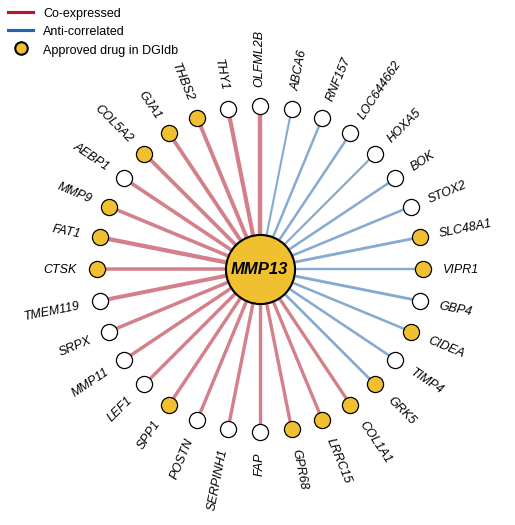

In [13]:
# [module-G]
import requests, networkx as nx
def dgidb(genes):
    q = """query($names:[String!]!){ genes(names:$names){ nodes{ name
           interactions{ interactionScore drug{ name approved } interactionTypes{ type } } } } }"""
    out = []
    for i in range(0, len(genes), 50):
        r = requests.post("https://dgidb.org/api/graphql", json={"query": q, "variables": {"names": genes[i:i + 50]}},
                          timeout=60)
        r.raise_for_status()
        for node in r.json()["data"]["genes"]["nodes"]:
            for it in node["interactions"]:
                out.append(dict(gene=node["name"], drug=it["drug"]["name"], approved=it["drug"]["approved"],
                                score=it.get("interactionScore"),
                                type=";".join(t["type"] for t in it["interactionTypes"] if t.get("type"))))
    return pd.DataFrame(out)

net_pos, net_neg = list(POS.index[:20]), list(NEG.index[:12])
try:
    DG = dgidb([TARGET] + net_pos + net_neg)
    DG.to_csv(os.path.join(DIRS["tables"], "T8_DGIdb_interactions.csv"), index=False)
    APPROVED = set(DG.loc[DG.approved == True, "gene"])
except Exception as e:
    DG, APPROVED = pd.DataFrame(), set(); print("DGIdb not reachable:", e)

G = nx.Graph()
for g in net_pos + net_neg:
    G.add_edge(TARGET, g, w=C.loc[g, "meta_rho"])
ring = net_pos + net_neg
ang0 = np.linspace(0, 2 * np.pi, len(ring), endpoint=False) + np.pi / 2
posn = {TARGET: np.array([0.0, 0.0])}
posn.update({g: np.array([np.cos(a), np.sin(a)]) for g, a in zip(ring, ang0)})
fig, ax = plt.subplots(figsize=(W1 * 1.25, W1 * 1.25))
for u, v, dd in G.edges(data=True):
    ax.plot(*zip(posn[u], posn[v]), color=POS_COL if dd["w"] > 0 else NEG_COL, lw=0.3 + 3 * abs(dd["w"]) ** 2,
            alpha=0.55, zorder=1)
for n_ in G.nodes:
    x_, y_ = posn[n_]
    if n_ == TARGET:
        ax.scatter(x_, y_, s=1100, color="#F0C030" if n_ in APPROVED else "black", edgecolor="black", zorder=2)
        ax.text(x_, y_, n_, color="black" if n_ in APPROVED else "white", ha="center", va="center", fontsize=8, fontstyle="italic", fontweight="bold")
        continue
    ax.scatter(x_, y_, s=60, color="#F0C030" if n_ in APPROVED else "white", edgecolor="black", lw=0.6, zorder=2)
    ang = np.degrees(np.arctan2(y_, x_)); r_ = 1.12
    ax.text(x_ * r_, y_ * r_, n_, fontsize=6, fontstyle="italic", ha="left" if x_ >= 0 else "right", va="center",
            rotation=ang if x_ >= 0 else ang - 180, rotation_mode="anchor")
ax.set_xlim(-1.55, 1.55); ax.set_ylim(-1.55, 1.55); ax.set_aspect("equal"); ax.axis("off")
ax.legend(handles=[Line2D([], [], color=POS_COL, lw=1.5, label="Co-expressed"),
                   Line2D([], [], color=NEG_COL, lw=1.5, label="Anti-correlated"),
                   Line2D([], [], marker="o", ls="", mfc="#F0C030", mec="black", label="Approved drug in DGIdb")],
          loc="upper left", bbox_to_anchor=(-0.02, 1.04), fontsize=6)
save(fig, "FigureS1_druggable_network", C.loc[net_pos + net_neg, ["meta_rho", "FDR"]]
     .assign(approved_drug_in_DGIdb=lambda x: x.index.isin(APPROVED)))
plt.show()

## Q · Age sensitivity (Supplementary Figures S2–S3)
Controls are younger than OA donors in every dataset with annotated age (Table S2).
**S2:** MMP13 OA-vs-control effect with and without adjustment for age (OLS: MMP13 ~ group + age).
**S3:** within-OA co-expression with MMP13 recomputed as partial Spearman correlation controlling for age.

Datasets with usable age: GSE117999, GSE57218, GSE98918, GSE55457, GSE51588
saved FigureS2_MMP13_age_adjusted  (.png/.tiff 300 dpi, .pdf vector)


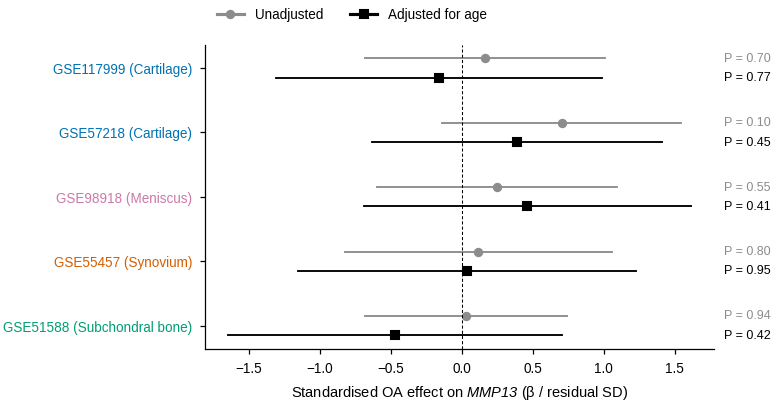

  dataset        model  n  beta_log2  lo_log2  hi_log2     p  r_group_age
GSE117999   unadjusted 24      0.207   -0.875    1.289 0.696        0.675
GSE117999 age-adjusted 24     -0.207   -1.687    1.273 0.774        0.675
 GSE57218   unadjusted 40      0.355   -0.070    0.779 0.099        0.566
 GSE57218 age-adjusted 40      0.195   -0.319    0.709 0.447        0.566
 GSE98918   unadjusted 24      0.396   -0.947    1.738 0.547        0.675
 GSE98918 age-adjusted 24      0.743   -1.111    2.597 0.414        0.675
 GSE55457   unadjusted 20      0.202   -1.424    1.829 0.797        0.613
 GSE55457 age-adjusted 20      0.063   -2.060    2.187 0.951        0.613
 GSE51588   unadjusted 50      0.050   -1.271    1.371 0.940        0.797
 GSE51588 age-adjusted 50     -0.876   -3.060    1.309 0.424        0.797
Genome-wide agreement (Spearman) between raw and age-partial meta ρ: 0.988
Top partners still significant (FDR<0.05, same sign) after age adjustment: 150/150 positive, 150/150 negative
s

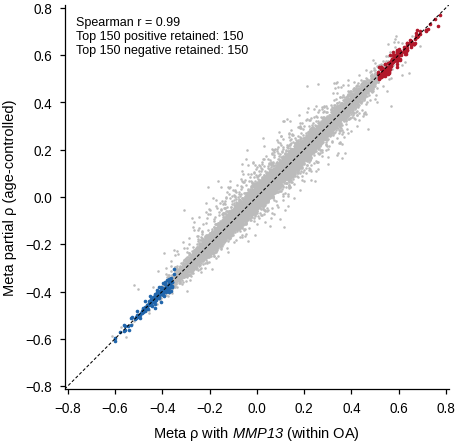

In [14]:
# [module-Q]
import statsmodels.api as sm

def get_age(acc):
    an = pd.read_csv(os.path.join(DIRS["proc"], f"{acc}_annotation.csv"), index_col=0)
    col = next((c for c in an.columns if re.search(r"^ch_(.*[^a-z])?age\b", c)), None)
    if col is None: return None
    return pd.to_numeric(an[col].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce")

AGES = {acc: get_age(acc) for acc in ordered_datasets()}
AGES = {k: v for k, v in AGES.items() if v is not None and v.reindex(DATA[k]["groups"].index).notna().mean() > 0.9}
print("Datasets with usable age:", ", ".join(AGES) or "none")

# --- S2: adjusted vs unadjusted
rowsQ = []
for acc in AGES:
    d = DATA[acc]; gr = d["groups"]; age = AGES[acc].reindex(gr.index)
    ok = age.notna()
    y = d["expr"].loc[TARGET, gr.index][ok].values
    oa = (gr[ok] == "OA").astype(float).values
    for label, X in [("unadjusted", np.column_stack([np.ones(ok.sum()), oa])),
                     ("age-adjusted", np.column_stack([np.ones(ok.sum()), oa, age[ok].values]))]:
        fit = sm.OLS(y, X).fit()
        sd = np.sqrt(fit.scale)
        rowsQ.append(dict(dataset=acc, tissue=d["tissue"], model=label, n=int(ok.sum()),
                          beta_log2=fit.params[1], lo_log2=fit.conf_int()[1][0], hi_log2=fit.conf_int()[1][1],
                          d_std=fit.params[1] / sd, d_lo=fit.conf_int()[1][0] / sd, d_hi=fit.conf_int()[1][1] / sd,
                          p=fit.pvalues[1], r_group_age=np.corrcoef(oa, age[ok].values)[0, 1]))
Q2 = pd.DataFrame(rowsQ)
Q2.to_csv(os.path.join(DIRS["tables"], "S3_MMP13_age_adjusted.csv"), index=False)

if len(Q2):
    order_q = [a for a in ordered_datasets() if a in AGES]
    fig, ax = plt.subplots(figsize=(W1 * 1.25, (len(order_q) * 9 + 22) * MM))
    for i, acc in enumerate(order_q):
        for off, (mdl, col, mk) in zip([0.15, -0.15], [("unadjusted", "#8C8C8C", "o"), ("age-adjusted", "black", "s")]):
            r = Q2[(Q2.dataset == acc) & (Q2.model == mdl)].iloc[0]
            yy = len(order_q) - 1 - i + off
            ax.plot([r.d_lo, r.d_hi], [yy, yy], color=col, lw=0.9)
            ax.plot(r.d_std, yy, mk, color=col, ms=3.5)
            ax.text(1.02, yy, f"P = {fmt_p(r.p)}", transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData),
                    va="center", fontsize=6, color=col)
    ax.axvline(0, color="black", lw=0.5, ls=(0, (3, 2)))
    ax.set_yticks(range(len(order_q))); ax.set_yticklabels([ds_label(a, False) for a in order_q[::-1]])
    for tl, a in zip(ax.get_yticklabels(), order_q[::-1]):
        tl.set_color(TISSUE_COL[DATA[a]["tissue"]])
    ax.set_xlabel(f"Standardised OA effect on {italic(TARGET)} (β / residual SD)")
    ax.legend(handles=[Line2D([], [], color="#8C8C8C", marker="o", ms=3.5, label="Unadjusted"),
                       Line2D([], [], color="black", marker="s", ms=3.5, label="Adjusted for age")],
              loc="upper left", bbox_to_anchor=(0, 1.16), ncol=2)
    save(fig, "FigureS2_MMP13_age_adjusted", Q2)
    plt.show()
    print(Q2[["dataset", "model", "n", "beta_log2", "lo_log2", "hi_log2", "p", "r_group_age"]].round(3).to_string(index=False))

# --- S3: partial (age-controlled) within-OA co-expression
def partial_spearman_vs(expr, vec, cov):
    R = expr.rank(axis=1).values.astype(float)
    v = stats.rankdata(vec).astype(float); c = stats.rankdata(cov).astype(float)
    Xc = np.column_stack([np.ones_like(c), c])
    H = Xc @ np.linalg.pinv(Xc)
    Rr = R - R @ H.T; vr = v - H @ v
    den = np.sqrt((Rr ** 2).sum(axis=1) * (vr ** 2).sum())
    return pd.Series((Rr @ vr) / np.where(den == 0, np.nan, den), index=expr.index)

RHO_P = RHO.copy()
for acc in AGES:
    d = DATA[acc]; gr = d["groups"]
    sub = d["expr"].loc[:, gr == "OA"] if (gr == "OA").sum() >= MIN_OA_FOR_COEXP else d["expr"]
    age = AGES[acc].reindex(sub.columns); ok = age.notna()
    sub = sub.loc[:, ok]; sub = sub.loc[sub.std(axis=1) > 0]
    RHO_P[acc] = partial_spearman_vs(sub, sub.loc[TARGET].values, age[ok].values).drop(TARGET, errors="ignore") \
                 .reindex(RHO.index)
ZdP = np.arctanh(RHO_P.clip(-0.999, 0.999))
ZcP = pd.DataFrame({c: ZdP[list(a.index)].mean(axis=1) for c, a in COHORT.groupby(COHORT)})
avP = ZcP.notna()
CP = pd.DataFrame({"meta_rho_partial": np.tanh((ZcP * Wc).sum(axis=1) / (avP * Wc).sum(axis=1)),
                   "meta_z_partial": (ZcP * Wc).sum(axis=1) / np.sqrt((avP * Wc).sum(axis=1))}).reindex(C.index)
CP["p"] = 2 * stats.norm.sf(CP.meta_z_partial.abs())
CP["FDR_partial"] = multipletests(CP.p.fillna(1), method="fdr_bh")[1]
CP = C[["meta_rho", "FDR"]].join(CP)
CP.to_csv(os.path.join(DIRS["tables"], "S4_coexpression_age_partial.csv"))
r_genes = CP[["meta_rho", "meta_rho_partial"]].dropna().corr(method="spearman").iloc[0, 1]
top_pos, top_neg = set(POS.index[:TOP_PARTNERS]), set(NEG.index[:TOP_PARTNERS])
still_pos = CP.loc[list(top_pos)].query("FDR_partial < 0.05 and meta_rho_partial > 0").shape[0]
still_neg = CP.loc[list(top_neg)].query("FDR_partial < 0.05 and meta_rho_partial < 0").shape[0]
AGE_SUMMARY = dict(r_genes=r_genes, still_pos=still_pos, n_pos=len(top_pos), still_neg=still_neg, n_neg=len(top_neg))
print(f"Genome-wide agreement (Spearman) between raw and age-partial meta ρ: {r_genes:.3f}")
print(f"Top partners still significant (FDR<0.05, same sign) after age adjustment: "
      f"{still_pos}/{len(top_pos)} positive, {still_neg}/{len(top_neg)} negative")

fig, ax = plt.subplots(figsize=(W1, W1 * 0.95))
xx_, yy_ = CP.meta_rho, CP.meta_rho_partial
ax.scatter(xx_, yy_, s=1.5, color="#BBBBBB", lw=0, rasterized=True)
ax.scatter(CP.loc[list(top_pos), "meta_rho"], CP.loc[list(top_pos), "meta_rho_partial"], s=3, color=POS_COL, lw=0)
ax.scatter(CP.loc[list(top_neg), "meta_rho"], CP.loc[list(top_neg), "meta_rho_partial"], s=3, color=NEG_COL, lw=0)
lim_ = np.nanmax(np.abs(np.r_[xx_.values, yy_.values])) * 1.05
ax.plot([-lim_, lim_], [-lim_, lim_], color="black", lw=0.5, ls=(0, (3, 2)))
ax.set_xlim(-lim_, lim_); ax.set_ylim(-lim_, lim_); ax.set_aspect("equal")
ax.set_xlabel(f"Meta ρ with {italic(TARGET)} (within OA)"); ax.set_ylabel("Meta partial ρ (age-controlled)")
ax.text(0.03, 0.97, f"Spearman r = {r_genes:.2f}\nTop {len(top_pos)} positive retained: {still_pos}\n"
        f"Top {len(top_neg)} negative retained: {still_neg}", transform=ax.transAxes, va="top", fontsize=6)
save(fig, "FigureS3_coexpression_age_partial", CP)
plt.show()

## H · Figure legends (auto-filled from results) + HTML report

In [15]:
# [module-H]
import base64
tissues_used = [t for t in TISSUE_ORDER if t in set(A.tissue)]
n_oa = int(sum((d["groups"] == "OA").sum() for d in DATA.values()))
n_ct = int(sum((d["groups"] == "Control").sum() for d in DATA.values()))
shared = [c for c, s in COHORT.groupby(COHORT) if len(s) > 1]
shared_txt = ("; " + "; ".join(f"{' and '.join(COHORT[COHORT == c].index)} derive from the same patients and were "
                               "averaged before pooling" for c in shared)) if shared else ""
mean_auc = B.groupby("feature").AUC.mean()

LEG = {}
LEG["Figure 1"] = (
    f"**Figure 1. MMP13 expression in osteoarthritic joint tissues.** (a) Forest plot of the standardised mean "
    f"difference (Hedges' g) in MMP13 expression between OA and control samples in {len(DATA)} GEO datasets "
    f"({', '.join(t.lower() for t in tissues_used)}; {n_oa} OA and {n_ct} control samples). Squares, dataset "
    f"estimates (size proportional to sample size) with 95% CIs; diamonds, random-effects estimates (DerSimonian–Laird τ², "
    f"Hartung–Knapp–Sidik–Jonkman 95% CI; tissue subtotals shown only for ≥ 3 datasets). The overall estimate is computed at cohort level (k = {META['k']}){shared_txt}. "
    f"Pooled g = {META['g']:.2f} (95% CI {META['lo']:.2f} to {META['hi']:.2f}), P = {fmt_pt(META['p'])}, "
    f"I² = {META['I2']:.0f}%. P values for individual datasets are from Welch's t-test. " + (
    "Median donor age (control vs OA) where annotated: " + "; ".join(
        f"{r.dataset} {r.control_median_age:.0f} vs {r.OA_median_age:.0f} years" for r in AGE.itertuples()) + ". "
    if len(AGE) else "") + f"(b) MMP13 log2 expression "
    f"relative to the control median in each dataset; boxes show median and interquartile range, whiskers 1.5 × IQR, "
    f"points individual samples.")
LEG["Figure 2"] = (
    f"**Figure 2. Protease–inhibitor balance indices do not outperform MMP13 alone.** (a) Area under the ROC curve "
    f"(AUC) for discriminating OA from control samples using MMP13 alone, the Catabolic Switch Index "
    f"(CSI = z[MMP13] − z[TIMP3]), the Matrix Turnover Balance (MTB = mean z of {', '.join(CATABOLIC)} minus mean z of "
    f"{', '.join(ANABOLIC)}) and a hypertrophy score (mean z of {', '.join(HYPERTROPHY)}). (b) Per-dataset AUCs "
    f"(coloured by tissue) and their mean (black): MMP13 {mean_auc.get('MMP13 alone', np.nan):.2f}, "
    f"CSI {mean_auc.get('CSI', np.nan):.2f}, MTB {mean_auc.get('MTB', np.nan):.2f}, hypertrophy score "
    f"{mean_auc.get('Hypertrophy score', np.nan):.2f}. Bootstrap 95% CIs (1,000 resamples) are given in Supplementary Table T2.")
LEG["Figure 3"] = (
    f"**Figure 3. A consensus MMP13 co-expression neighbourhood in OA tissue.** Spearman correlations with MMP13 "
    f"were computed within OA samples of each dataset (all samples where fewer than {MIN_OA_FOR_COEXP} OA samples "
    f"were available), Fisher-transformed, averaged within cohorts and combined across {Zc.shape[1]} cohorts by "
    f"sample-size-weighted Stouffer meta-analysis. (a) Meta correlation versus significance for {len(C):,} genes; "
    f"coloured points are robust partners (Benjamini–Hochberg FDR < 0.05 and the same sign in ≥ 75% of cohorts; "
    f"{len(POS)} positive, {len(NEG)} negative). (b) Per-dataset and meta correlations of the 25 strongest positive "
    f"and 15 strongest negative partners.")
LEG["Figure 4"] = (
    f"**Figure 4. Coupling of MMP13 to matrix and hypertrophy programmes within OA tissue.** (a) Spearman correlation "
    f"of MMP13 with catabolic, anabolic and hypertrophy genes in each dataset and the meta estimate. Asterisks "
    f"(one, two, three) denote P < 0.05, < 0.01 and < 0.001 (dataset columns, correlation test) or the same "
    f"thresholds on BH-FDR (meta column). (b) MMP13 "
    f"versus hypertrophy score in OA samples (z-scores computed within each dataset; n = {len(pooled)}); "
    f"Spearman ρ = {r_all:.2f}, P = {fmt_pt(p_all)}. Line, least-squares fit for illustration.")
if len(GS_META):
    LEG["Figure 5"] = (
        f"**Figure 5. Hallmark programmes tracking MMP13 within OA tissue.** (a) Pre-ranked GSEA (MSigDB Hallmark 2020, "
        f"{GSEA_PERMUTATIONS:,} permutations) of all {len(C):,} genes ranked by their cohort-level co-expression meta-z "
        f"with MMP13 (Figure 3). Gene sets with FDR < 0.05 are shown (at most 12 per direction); bars, normalised "
        f"enrichment score (NES). " + (
        f"(b) Sensitivity analysis in datasets with ≥ {MIN_OA_FOR_ENDO} OA samples: top versus bottom MMP13 tertile "
        f"(Welch's t ranking, pre-ranked GSEA). Colour, NES; size, −log10 FDR; black outline, FDR < 0.05."
        if len(NES) else ""))
if False:
    LEG["Figure 5"] = (
        f"**Figure 5. Hallmark programmes distinguishing MMP13-high from MMP13-low OA samples.** Within OA samples of "
        f"datasets with ≥ {MIN_OA_FOR_ENDO} OA samples, the top and bottom MMP13 tertiles were compared (Welch's t), and "
        f"genes ranked by t were analysed by pre-ranked GSEA against MSigDB Hallmark 2020 ({GSEA_PERMUTATIONS:,} "
        f"permutations). Shown are gene sets with FDR < 0.05 in at least one dataset. Colour, normalised enrichment "
        f"score (NES); size, −log10 FDR; black outline, FDR < 0.05. Group sizes (high vs low) are given under each dataset.")
if len(ENR):
    LEG["Figure 6"] = (
        f"**Figure 6. Transcriptional regulators and pathways over-represented in the MMP13 neighbourhood.** Enrichr "
        f"analysis of the top {TOP_PARTNERS} positively (a) and negatively (b) correlated robust partners against "
        f"TRRUST 2019, ChEA 2022, Reactome 2022 and GO Biological Process 2023, using all {len(C):,} tested genes as "
        f"background. Up to four terms per library with adjusted P < 0.05 are shown; dot size reflects the number "
        f"of overlapping genes.")
if len(PAIR):
    _pa = PAIR.set_index("feature")
    LEG["Figure 7"] = (
        f"**Figure 7. Within-patient comparison of lesioned and macroscopically preserved cartilage.** Paired samples "
        f"from {int(_pa.n_pairs.iloc[0])} OA patients ({PAIR.dataset.iloc[0]}). (a) MMP13 expression; (b, c) mean z-score of "
        f"the 50 strongest positively and negatively co-expressed MMP13 partners, derived without this cohort "
        f"(leave-one-cohort-out). Lines connect samples from the same patient (red, higher in lesioned; blue, lower); "
        f"black bars, medians. P values, Wilcoxon signed-rank test: "
        + "; ".join(f"{k} P = {fmt_pt(r.wilcoxon_p)}" for k, r in _pa.iterrows()) + ".")
if len(Q2):
    _q = Q2.pivot(index="dataset", columns="model", values="p")
    LEG["Figure S2"] = (
        f"**Supplementary Figure S2. Age sensitivity of the MMP13 OA–control difference.** In datasets with annotated "
        f"donor age ({', '.join(AGES)}), MMP13 was modelled by ordinary least squares as MMP13 ~ group (unadjusted) and "
        f"MMP13 ~ group + age (adjusted). Points, standardised group coefficient (β divided by residual SD) with 95% CI. "
        + "; ".join(f"{a}: P = {fmt_pt(r['unadjusted'])} unadjusted, {fmt_pt(r['age-adjusted'])} adjusted"
                    for a, r in _q.iterrows()) + ". Group and age are partly collinear (Table S3, r_group_age).")
    LEG["Figure S3"] = (
        ("**Supplementary Figure S3. The MMP13 co-expression neighbourhood is robust to donor age.** "
         if (AGE_SUMMARY["r_genes"] >= 0.9 and AGE_SUMMARY["still_pos"] >= 0.8 * AGE_SUMMARY["n_pos"]
             and AGE_SUMMARY["still_neg"] >= 0.8 * AGE_SUMMARY["n_neg"])
         else "**Supplementary Figure S3. Effect of donor age on the MMP13 co-expression neighbourhood.** ") +
        f"Within-OA "
        f"co-expression with MMP13 recomputed as partial Spearman correlation controlling for age in datasets with "
        f"annotated age ({', '.join(AGES)}; other datasets unchanged) and meta-analysed as in Figure 3. Genome-wide "
        f"agreement between raw and age-partial meta ρ, Spearman r = {AGE_SUMMARY['r_genes']:.2f}. Of the top "
        f"{AGE_SUMMARY['n_pos']} positive and {AGE_SUMMARY['n_neg']} negative partners, {AGE_SUMMARY['still_pos']} and "
        f"{AGE_SUMMARY['still_neg']} remained significant with the same sign (BH-FDR < 0.05). Coloured points, top partners "
        f"from Figure 3; dashed line, identity.")
LEG["Figure S1"] = (
    f"**Supplementary Figure S1. MMP13 consensus partners with drug-interaction records.** The 20 strongest positive "
    f"and 12 strongest negative partners; edge width scales with |meta ρ|. Yellow nodes have at least one approved "
    f"drug interaction recorded in DGIdb (accessed {RUN_STAMP[:10]}). Records indicate database interactions, not "
    f"evidence of efficacy in OA.")

with open(os.path.join(DIRS["report"], "Figure_legends.md"), "w", encoding="utf-8") as f:
    f.write(f"# Figure legends — generated {RUN_STAMP}\n\n" + "\n\n".join(LEG.values()) + "\n")
pd.DataFrame(FIG_LOG).to_csv(os.path.join(DIRS["report"], "figure_dimensions.csv"), index=False)

def img(name):
    p = os.path.join(DIRS["figs"], name + ".png")
    return f'<img src="data:image/png;base64,{base64.b64encode(open(p, "rb").read()).decode()}">' if os.path.exists(p) else ""
figmap = {"Figure 1": "Figure1_MMP13_cross_tissue", "Figure 2": "Figure2_balance_indices",
          "Figure 3": "Figure3_MMP13_neighbourhood", "Figure 4": "Figure4_programme_coupling",
          "Figure 5": "Figure5_MMP13_hallmark_programmes", "Figure 6": "Figure6_upstream_and_pathways",
          "Figure 7": "Figure7_lesioned_vs_preserved", "Figure S1": "FigureS1_druggable_network",
          "Figure S2": "FigureS2_MMP13_age_adjusted", "Figure S3": "FigureS3_coexpression_age_partial"}
def strip_bold(v):
    return re.sub(r"^\*\*(.+?)\*\*", r"\1", v)
body = "".join("<section>" + img(figmap[k]) + "<p>" + strip_bold(v) + "</p></section>" for k, v in LEG.items())
html_doc = f"""<!doctype html><html><head><meta charset="utf-8"><title>MMP13-OA discovery analysis · MMP13 in OA</title>
<style>body{{font-family:Arial,Helvetica,sans-serif;max-width:980px;margin:32px auto;padding:0 16px;color:#222;
line-height:1.45;font-size:14px}} h1{{font-size:22px}} img{{max-width:100%;border:1px solid #eee;margin-top:24px}}
table{{border-collapse:collapse;font-size:12px}} td,th{{border:1px solid #ddd;padding:3px 6px}}</style></head><body>
<h1>MMP13-OA discovery analysis — MMP13 in osteoarthritis</h1><p>Generated {RUN_STAMP}</p>
<h2>Datasets</h2>{AUDIT.to_html(index=False)}<h2>Figures</h2>{body}</body></html>"""
open(os.path.join(DIRS["report"], "MMP13OA_discovery_report.html"), "w", encoding="utf-8").write(html_doc)
json.dump(dict(run=RUN_STAMP, target=TARGET, datasets=DATASETS, gsea_perm=GSEA_PERMUTATIONS, n_boot=N_BOOT,
               seed=SEED, font=FONT), open(os.path.join(DIRS["report"], "run_parameters.json"), "w"),
          indent=2, default=str)
print("\n\n".join(strip_bold(v) for v in LEG.values()))

Figure 1. MMP13 expression in osteoarthritic joint tissues. (a) Forest plot of the standardised mean difference (Hedges' g) in MMP13 expression between OA and control samples in 7 GEO datasets (cartilage, meniscus, synovium, subchondral bone; 123 OA and 66 control samples). Squares, dataset estimates (size proportional to sample size) with 95% CIs; diamonds, random-effects estimates (DerSimonian–Laird τ², Hartung–Knapp–Sidik–Jonkman 95% CI; tissue subtotals shown only for ≥ 3 datasets). The overall estimate is computed at cohort level (k = 6); GSE117999 and GSE98918 derive from the same patients and were averaged before pooling. Pooled g = 0.69 (95% CI -0.39 to 1.77), P = 0.16, I² = 67%. P values for individual datasets are from Welch's t-test. Median donor age (control vs OA) where annotated: GSE117999 52 vs 64 years; GSE57218 18 vs 67 years; GSE98918 52 vs 64 years; GSE55457 57 vs 73 years; GSE51588 35 vs 68 years. (b) MMP13 log2 expression relative to the control median in each data

## I · Download all v2 results as one zip

In [16]:
# [step-I-download]
import zipfile, shutil
zip_path = f"/content/MMP13OA_discovery_results_{datetime.datetime.now():%Y%m%d_%H%M}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for key in ["tables", "figs", "report"]:
        for dp, _, fns in os.walk(DIRS[key]):
            for fn in fns:
                full = os.path.join(dp, fn); z.write(full, arcname=os.path.relpath(full, BASE))
shutil.copy(zip_path, BASE)
print(f"{os.path.getsize(zip_path) / 1e6:.1f} MB → {zip_path}")
try:
    from google.colab import files; files.download(zip_path)
except ImportError:
    pass

11.9 MB → /content/MMP13OA_discovery_results_20261012_1651.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>